## ==========================================================================
## PROJECT OVERVIEW - TRAINING
## ==========================================================================
##
## This notebook trains a YOLO-based object detection model on a basketball dataset. The proposed model is designed to detect a single object class: the basketball.
##
## The objective is to develop a specialized detector and compare its performance against a pre-trained multi-class basketball detection model obtained from GitHub.
##
## The resulting model will later be evaluated in terms of both detection accuracy and computational efficiency.
## ==========================================================================

## 1 · INSTALL DEPENDENCIES

### 1.1 · Install packages and libraries

In [ ]:
%%capture install_log
# Install all required packages quietly
!pip install ultralytics roboflow supervision opencv-python PyYAML tqdm matplotlib pandas

### 1.2 · Import modules

In [ ]:
from datetime import datetime
from math import pi
from google.colab import drive, userdata
from pathlib import Path
from roboflow import Roboflow
from tabulate import tabulate
from tqdm.notebook import tqdm
from typing import Any, Dict, List, Optional
from ultralytics import YOLO

import csv, datetime, glob, json, logging, os, random, re, shutil, subprocess, sys, time, torch, yaml

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


# ── Logging configuration ──────────────────────────────────────────────────
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s [%(levelname)s] %(message)s',
    handlers=[logging.StreamHandler(sys.stdout)]
)
logger = logging.getLogger(__name__)
logger.info("Imports OK.")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


## 2 · GPU & ENVIRONMENT VERIFICATION

In [ ]:
def verify_environment() -> Dict[str, Any]:
    """Check GPU availability, VRAM, and print a concise environment report."""
    info: Dict[str, Any] = {
        "python_version": sys.version.split()[0],
        "torch_version": torch.__version__,
        "cuda_available": torch.cuda.is_available(),
        "gpu_count": torch.cuda.device_count() if torch.cuda.is_available() else 0,
    }

    if info["cuda_available"]:
        idx = torch.cuda.current_device()
        vram_gb = torch.cuda.get_device_properties(idx).total_memory / 1e9
        info["gpu_name"]   = torch.cuda.get_device_name(idx)
        info["vram_gb"]    = round(vram_gb, 2)
        info["cuda_version"] = torch.version.cuda
        logger.info(f"✅  GPU: {info['gpu_name']} — {info['vram_gb']} GB VRAM")
    else:
        logger.warning("⚠️  No GPU detected — training will be very slow on CPU.")

    for k, v in info.items():
        print(f"  {k:20s}: {v}")
    return info

env_info = verify_environment()

  python_version      : 3.12.13
  torch_version       : 2.11.0+cu128
  cuda_available      : True
  gpu_count           : 1
  gpu_name            : Tesla T4
  vram_gb             : 15.64
  cuda_version        : 12.8


## 3 · USER CONFIGURATION



**Parameters Table** :
The table below shows the parameters used for all the versions.

| Category | Parameter | v1 | v2 | v3 | v4 | v5 | Reason for Change / Note |
|:---|:---|:---:|:---:|:---:|:---:|:---:|:---|
| **Core** | `model` | yolo26s.pt | yolo26s.pt | v2 checkpoint | yolo26s.pt | v4 checkpoint | v3 is a refinement stage for v2 as v5 is for v4 |
| **Core** | `data` |  ball_1858.yolo26  | ball_1858.yolo26  | ball_1858.yolo26 | ball_1858.yolo26 | ball_1858.yolo26 | Updated dataset maintained |
| **Core** | `epochs` | 60 | 60 | 10 | 100 | 20 | Extended search/training in v4; short fine-tuning in v5 |
| **Core** | `batch` | 8 | 8 | 8 | Auto (8–32 VRAM dependent) | ½ of v4 batch (min 4) | Adaptive VRAM utilization; reduced for high-resolution refinement |
| **Core** | `imgsz` | 640 | 640 | 960 | 640 | 960 | v4 optimized at standard resolution; v5 refines localization at high resolution |
| **Core** | `device` | '0' | '0' | '0' | Auto CUDA/CPU | Auto CUDA/CPU | Environment-aware device selection |
| **Performance** | `workers` | 2 | 2 | 2 | 2 | 2 | Unchanged |
| **Performance** | `amp` | True | True | True | True | True | Mixed precision retained |
| **Optimizer** | `optimizer` | SGD | SGD | SGD | SGD | SGD | Unchanged |
| **Optimizer** | `lr0` | 0.01 | 0.005 | 0.001 | 0.00387 | 0.001 | Very low LR in v5 for stable refinement |
| **Optimizer** | `lrf` | 0.01 | 0.01 | 0.01 | 0.01 | 0.01 | Higher final LR ratio for short refinement |
| **Optimizer** | `momentum` | 0.937 | 0.937 | 0.937 | 0.937 | 0.937 | Unchanged |
| **Optimizer** | `weight_decay` | 0.0005 | 0.0005 | 0.0005 | 0.00178 | 0.00178 | Increased in v4 and v5 |
| **Optimizer** | `warmup_epochs` | 2.0 | 3.0 | 3.0 | 3.0 | 3.0 | Warmup removed during refinement |
| **Regularization** | `patience` | 10 | 10 | 5 | 5 | 5 | More tolerance for convergence |
| **Regularization** | `dropout` | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | Unchanged |
| **Augmentation** | `augment` | True | True | True | True | True | Unchanged |
| **Augmentation** | `hsv_h` | 0.015 | 0.015 | 0.015 | 0.015 | 0.015 | Unchanged |
| **Augmentation** | `hsv_s` | 0.3 | 0.3 | 0.3 | 0.41510 | 41510 | Lighter color augmentation in v4 and v5 |
| **Augmentation** | `hsv_v` | 0.2 | 0.2 | 0.2 | 0.30856 | 0.30856 | Lighter color augmentation in v4 and v5 |
| **Augmentation** | `degrees` | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | Unchanged |
| **Augmentation** | `translate` | 0.03 | 0.03 | 0.03 | 0.03 | 0.03 | Reduced for fine localization |
| **Augmentation** | `scale` | 0.3 | 0.3 | 0.15 | 0.07243 | 0.07243 | Reduced in v4 and v5 |
| **Augmentation** | `shear` | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | Unchanged |
| **Augmentation** | `flipud` | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | Unchanged |
| **Augmentation** | `fliplr` | 0.5 | 0.5 | 0.5 | 0.5 | 0.5 | Unchanged |
| **Augmentation** | `mosaic` | 0.5 | 0.3 | 0.0 | 0.0 | 0.0 | Set the parameter found during search |
| **Augmentation** | `mixup` | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | Reintroduced by optimization in v4 and v5 |
| **Augmentation** | `copy_paste` | — | — | — | 0.13246 | 0.13246 | Added via hyperparameter search |
| **Augmentation** | `erasing` | — | — | — | 0.53990 | 0.53990 | Added via hyperparameter search |
| **Augmentation** | `close_mosaic` | 8 | 8 | 10 | 10 | 10 | Increased in v4 and v5 |
| **Logging** | `save_period` | 5 | 5 | 5 | 5 | 5 | Unchanged |
| **Logging** | `project` | yolo_ball | yolo_ball | yolo_ball | PROJECT | PROJECT | Consistent workspace organization |
| **Logging** | `name` | train_v1 | train_v2 | train_v3 | train_v4 | train_v5 | Experiment tracking |
| **Logging** | `exist_ok` | True | True | True | True | True | Unchanged |
| **Logging** | `verbose` | True | True | True | True | True | Unchanged |
| **Loss** | `box` | 10.0 | 10.0 | 10.0 | 12.37823 | 12.37823 | Hyperparameter-optimized localization weight |
| **Loss** | `cls` | 0.5 | 0.5 | 0.5 | 0.5 | 0.5 | Unchanged |
| **Loss** | `dfl` | 2.0 | 2.0 | 2.0 | 2.78799 | 2.78799 | Optimized distribution focal loss |
| **Loss** | `cls_pw` | — | — | — | 0.55141 | 0.55141 | Added through hyperparameter optimization to rebalance classification loss |


In [ ]:
PROJECT= "yolo_ball"
NAME="train_v5"

drive.mount('/content/drive')

# If True -> load hyperparameters from YAML file
USE_YAML_CONFIG = False

# Path of YAML config to load
YAML_CONFIG_PATH = Path("/content/drive/MyDrive/DeepLearning")/PROJECT/NAME/"cfg.yaml"

# If True -> save final HYPERPARAMS dict as YAML
SAVE_CONFIG_TO_YAML = False

# Output YAML path
OUTPUT_YAML_PATH = Path("/content/drive/MyDrive/DeepLearning")/PROJECT/NAME/"cfg.yaml"

Mounted at /content/drive


In [ ]:
# ╔══════════════════════════════════════════════════════════════╗
# ║               TRAINING HYPERPARAMETERS                       ║
# ╚══════════════════════════════════════════════════════════════╝

# Auto-size batch size VRAM is available
_vram = env_info.get("vram_gb", 0)

# Better auto-batch logic for T4 / A100 / L4
if _vram >= 20:
    _auto_batch = 32
elif _vram >= 15:
    _auto_batch = 24
elif _vram >= 10:
    _auto_batch = 16
else:
    _auto_batch = 8

imgsz = 960

DEFAULT_HYPERPARAMS: Dict[str, Any] = {

    # ── Core ──────────────────────────────────────────────────

    # Number of training epochs. One epoch corresponds to a full pass
    # over the training dataset.
    "epochs": 20,

    # Batch size. If set to an auto-computed value, YOLO selects the
    # largest batch that fits in available GPU memory.
    "batch": _auto_batch,

    # Input image resolution used for both training and validation.
    # Higher values improve small-object detection at higher cost.
    "imgsz": imgsz,

    # Training device. Uses the first CUDA GPU if available,
    # otherwise falls back to CPU execution.
    "device": 0 if env_info["cuda_available"] else "cpu",


    # ── Performance ───────────────────────────────────────────

    # Number of dataloader worker processes used for image loading
    # and preprocessing.
    "workers": 2,

    # Enables Automatic Mixed Precision (FP16) to reduce memory usage
    # and accelerate training on compatible GPUs.
    "amp": True,


    # ── Optimizer ─────────────────────────────────────────────

    # Optimization algorithm used to update model weights.
    # SGD often provides stable convergence for detection tasks.
    "optimizer": "SGD",

    # Initial learning rate at the start of training.
    # Controls the size of weight updates.
    "lr0": 0.001,

    # Final learning-rate multiplier relative to lr0.
    # Defines how aggressively the scheduler decays the LR.
    "lrf": 0.01,

    # Momentum coefficient for SGD. Helps smooth optimization
    # and accelerates convergence.
    "momentum": 0.937,

    # L2 regularization applied to model weights to reduce overfitting
    # and improve generalization.
    "weight_decay": 0.0017799097234512333,

    # Number of warmup epochs during which learning rate and momentum
    # are gradually ramped up.
    "warmup_epochs": 3.0,


    # ── Regularisation ────────────────────────────────────────

    # Early stopping patience. Training stops if validation metrics
    # do not improve for this many epochs.
    "patience": 5,

    # Dropout probability applied inside supported model layers.
    # Helps prevent overfitting.
    "dropout": 0.0,


    # ── Augmentation ──────────────────────────────────────────

    # Enables data augmentation during training.
    "augment": True,


    # Color augmentation

    # Random hue shift applied to training images.
    # Improves robustness to color variations.
    "hsv_h": 0.015,

    # Random saturation scaling factor.
    # Simulates different lighting and camera conditions.
    "hsv_s": 0.4150971457144297,

    # Random brightness/value scaling factor.
    # Improves robustness to illumination changes.
    "hsv_v": 0.3085612973665453,


    # Geometric augmentation

    # Maximum random image rotation in degrees.
    # Useful when objects may appear rotated.
    "degrees": 0.0,

    # Maximum random translation as a fraction of image size.
    # Simulates object displacement in the frame.
    "translate": 0.03,

    # Random scaling factor applied to images.
    # Helps the model learn scale invariance.
    "scale": 0.07243332970372798,

    # Maximum shear transformation.
    # Introduces perspective-like distortions.
    "shear": 0.0,


    # Flips

    # Probability of vertical flipping.
    # Usually disabled for natural-image detection tasks.
    "flipud": 0.0,

    # Probability of horizontal flipping.
    # Commonly beneficial when object orientation is symmetric.
    "fliplr": 0.5,


    # Advanced augmentation

    # Probability of applying Mosaic augmentation, which combines
    # four images into a single training sample.
    "mosaic": 0.2314995340155008,

    # Probability of MixUp augmentation, blending two images
    # and their labels together.
    "mixup": 0.06535447710895495,

    # Probability of Copy-Paste augmentation, which copies labeled
    # objects between images.
    "copy_paste": 0.1324573582071444,

    # Randomly removes image regions during training to improve
    # robustness to occlusions.
    "erasing": 0.539904994336854,


    # Mosaic scheduling

    # Number of final epochs during which Mosaic is disabled.
    # Allows the model to fine-tune on more realistic images.
    "close_mosaic": 10,


    # ── Checkpointing & Logging ───────────────────────────────

    # Save a checkpoint every N epochs.
    # Useful for monitoring and recovery.
    "save_period": 5,

    # Root directory where training runs are stored.
    "project": PROJECT,

    # Name of the current experiment/run.
    "name": NAME,

    # Allows overwriting an existing run directory if it already exists.
    "exist_ok": True,

    # Enables detailed training logs and progress output.
    "verbose": True,


    # ── Loss tuning ───────────────────────────────────────────

    # Weight assigned to the bounding-box regression loss.
    # Higher values prioritize localization accuracy.
    "box": 12.378231799898314,

    # Weight assigned to the classification loss.
    # Controls the importance of correct class prediction.
    "cls": 0.5,

    # Weight assigned to Distribution Focal Loss (DFL),
    # used for more precise bounding-box localization.
    "dfl": 2.787988256670626,

    # Positive-class weighting factor for classification loss.
    # Can help address class imbalance.
    "cls_pw": 0.5514069234693977,
}

dataset_name = "ball_1858.yolo26"

# Model selection
MODEL_WEIGHTS = Path("/content/drive/MyDrive/DeepLearningProject/yolo_ball/train_v4/completed/best.pt") # "yolo26s.pt"   # use yolo26m.pt if VRAM >= 16GB

print(f"Batch size set to: {DEFAULT_HYPERPARAMS['batch']} (VRAM: {_vram} GB)")
print("✅ Updated hyperparameters loaded")
print("Best achieved mAP50-95(B): 0.71875")

Batch size set to: 24 (VRAM: 15.64 GB)
✅ Updated hyperparameters loaded
Best achieved mAP50-95(B): 0.71875


## 4 · MODEL INITIALIZATION

In [ ]:
def load_model(weights: str = "yolo26s.pt") -> YOLO:
    """
    Download (if needed) and load YOLOv11 pretrained weights.
    Prints a brief architecture summary.
    """
    logger.info(f"Loading model: {weights}")
    model = YOLO(weights)   # auto-downloads from Ultralytics HUB on first call

    # ── Parameter count ──────────────────────────────────────────────────
    total_params  = sum(p.numel() for p in model.model.parameters())
    train_params  = sum(p.numel() for p in model.model.parameters() if p.requires_grad)

    logger.info(f"Architecture    : {model.type}")
    logger.info(f"Total params    : {total_params:,}")
    logger.info(f"Trainable params: {train_params:,}")
    return model

model = load_model(MODEL_WEIGHTS)

## 5 · DATASET ACQUISITION

### 5.1 · Load the right path to the dataset

In [ ]:
# =========================================================
# CONFIG
# =========================================================

DATASET_NAME = dataset_name

# Possible dataset locations
POSSIBLE_DATASET_DIRS = [
    Path(f"/content/drive/MyDrive/DeepLearningProject/datasets/{DATASET_NAME}"),
    Path(f"/content/drive/Shareddrives/DeepLearningProject/datasets/{DATASET_NAME}"),
    Path(f"/content/drive/SharedWithMe/DeepLearningProject/datasets/{DATASET_NAME}"),

]

# Expected structure
EXPECTED_ITEMS = [
    "train",
    "data.yaml",
    "README.roboflow.txt"
]

# =========================================================
# MOUNT DRIVE
# =========================================================

drive.mount('/content/drive')

# =========================================================
# VALIDATION
# =========================================================

def dataset_is_valid(dataset_dir: Path) -> bool:
    """
    Check if dataset exists and contains expected structure.
    """
    if not dataset_dir.exists():
        return False

    for item in EXPECTED_ITEMS:
        if not (dataset_dir / item).exists():
            return False

    return True

# =========================================================
# FIND DATASET
# =========================================================

def find_dataset() -> Path:
    """
    Search dataset in all possible locations.
    """
    for path in POSSIBLE_DATASET_DIRS:
        if dataset_is_valid(path):
            return path

    return None

# =========================================================
# INSPECT CONTENTS
# =========================================================

def inspect_dataset(dataset_dir: Path):
    """
    Print dataset structure.
    """
    print("\nDataset root contents:")
    for item in sorted(dataset_dir.iterdir()):
        print(" -", item.name)

    train_dir = dataset_dir / "train"
    if train_dir.exists():
        print("\nTrain folder contents:")
        for item in sorted(train_dir.iterdir()):
            print(" -", item.name)

# =========================================================
# MAIN
# =========================================================

def get_dataset() -> Path:

    dataset_dir = find_dataset()

    if dataset_dir is None:
        print("\n❌ Dataset not found in any known location.")
        print("\nChecked paths:")
        for p in POSSIBLE_DATASET_DIRS:
            print(" -", p)

        print("Please add the directory DeepLearningProject directory to MyDrive directory with a shortcut, or change the path in the code")

        raise FileNotFoundError("Dataset missing or invalid structure.")

    print("\n✅ Dataset found!")
    print(f"Path: {dataset_dir}")

    inspect_dataset(dataset_dir)

    return dataset_dir

# =========================================================
# RUN
# =========================================================

dataset_path = get_dataset()

print("\nFINAL DATASET PATH:")
print(dataset_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

✅ Dataset found!
Path: /content/drive/MyDrive/DeepLearningProject/datasets/ball_1858.yolo26

Dataset root contents:
 - README.roboflow.txt
 - data.yaml
 - test
 - train
 - valid

Train folder contents:
 - images
 - labels

FINAL DATASET PATH:
/content/drive/MyDrive/DeepLearningProject/datasets/ball_1858.yolo26


### 5.2 · Check if the dataset is divided in the typical 3 subsets. If not, create the partition

In [ ]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# ─────────────────────────────────────────────
# Helpers
# ─────────────────────────────────────────────

def list_images(folder: Path):
    return [p for p in folder.iterdir() if p.suffix.lower() in IMG_EXTS]


def count_subset(dataset_path: Path):
    def count(p: Path):
        return len(list(p.glob("*"))) if p.exists() else 0

    return {
        "train_images": count(dataset_path / "train" / "images"),
        "train_labels": count(dataset_path / "train" / "labels"),
        "valid_images": count(dataset_path / "valid" / "images"),
        "valid_labels": count(dataset_path / "valid" / "labels"),
        "test_images": count(dataset_path / "test" / "images"),
        "test_labels": count(dataset_path / "test" / "labels"),
    }


def print_stats(title: str, stats: dict):
    total_img = stats["train_images"] + stats["valid_images"] + stats["test_images"]

    print(f"\n{title}")
    print(f"   Train: {stats['train_images']} imgs | {stats['train_labels']} labels")
    print(f"   Valid: {stats['valid_images']} imgs | {stats['valid_labels']} labels")
    print(f"   Test : {stats['test_images']} imgs | {stats['test_labels']} labels")
    print(f"   TOTAL images: {total_img}\n")


def move_pair(img_path: Path, src_img: Path, src_lbl: Path,
              dst_img: Path, dst_lbl: Path):

    dst_img.mkdir(parents=True, exist_ok=True)
    dst_lbl.mkdir(parents=True, exist_ok=True)

    shutil.move(str(img_path), str(dst_img / img_path.name))

    label = src_lbl / f"{img_path.stem}.txt"
    if label.exists():
        shutil.move(str(label), str(dst_lbl / label.name))
    else:
        print(f"⚠️ Missing label: {label.name}")


# ─────────────────────────────────────────────
# Main split logic
# ─────────────────────────────────────────────

def verify_and_split_dataset(dataset_path: Path, seed: int = 42):

    train_img = dataset_path / "train" / "images"
    train_lbl = dataset_path / "train" / "labels"

    val_img = dataset_path / "valid" / "images"
    val_lbl = dataset_path / "valid" / "labels"

    test_img = dataset_path / "test" / "images"
    test_lbl = dataset_path / "test" / "labels"

    # ── BEFORE STATS ─────────────────────────
    before = count_subset(dataset_path)
    print_stats("BEFORE SPLIT", before)

    # ── check if split already exists ────────
    if val_img.exists() and test_img.exists():
        print("✅ Dataset already has valid/test folders. No split needed.")
        return

    print("⚠️ valid/test missing → creating 80/10/10 split from train...")

    images = list_images(train_img)
    if not images:
        raise FileNotFoundError(f"No images found in {train_img}")

    random.seed(seed)
    random.shuffle(images)

    n = len(images)

    # FIX: ensure test is never lost due to rounding
    n_train = int(n * 0.8)
    n_val = int(n * 0.1)
    n_test = n - n_train - n_val  # force remainder into test

    train_set = images[:n_train]
    val_set = images[n_train:n_train + n_val]
    test_set = images[n_train + n_val:]

    print("Split plan:")
    print(f"   Train: {len(train_set)}")
    print(f"   Valid: {len(val_set)}")
    print(f"   Test : {len(test_set)}")

    # ── MOVE FILES ───────────────────────────
    for img in val_set:
        move_pair(img, train_img, train_lbl, val_img, val_lbl)

    for img in test_set:
        move_pair(img, train_img, train_lbl, test_img, test_lbl)

    # ── AFTER STATS ──────────────────────────
    after = count_subset(dataset_path)
    print_stats("AFTER SPLIT", after)

    print("✅ Dataset split completed successfully.")


# ─────────────────────────────────────────────
# YAML validation
# ─────────────────────────────────────────────

def validate_data_yaml(dataset_path: Path) -> Path:

    yaml_path = dataset_path / "data.yaml"

    if yaml_path.exists():
        with yaml_path.open() as f:
            cfg = yaml.safe_load(f)

        print(f"✅ data.yaml found — classes: {cfg.get('nc', '?')}")
        return yaml_path

    print("⚠️ data.yaml missing → creating default one")

    cfg = {
        "train": str(dataset_path / "train" / "images"),
        "val": str(dataset_path / "valid" / "images"),
        "test": str(dataset_path / "test" / "images"),
        "nc": 1,
        "names": ["object"],
    }

    with yaml_path.open("w") as f:
        yaml.dump(cfg, f)

    return yaml_path


# ─────────────────────────────────────────────
# RUN
# ─────────────────────────────────────────────

verify_and_split_dataset(dataset_path)

data_yaml_path = validate_data_yaml(dataset_path)

print(f"\ndata.yaml path: {data_yaml_path}")


BEFORE SPLIT
   Train: 1485 imgs | 1499 labels
   Valid: 185 imgs | 185 labels
   Test : 187 imgs | 187 labels
   TOTAL images: 1857

✅ Dataset already has valid/test folders. No split needed.
✅ data.yaml found — classes: 1

data.yaml path: /content/drive/MyDrive/DeepLearningProject/datasets/ball_1858.yolo26/data.yaml


### 5.3 · Dataset validation

In [ ]:
# ── Validate that dataset nc == model nc (before training starts) ──────────
def check_class_count_consistency(data_yaml: Path, model: YOLO) -> None:
    """Assert that the YAML class count matches what the model expects."""
    with data_yaml.open() as f:
        cfg = yaml.safe_load(f)
    yaml_nc  = cfg.get("nc", -1)
    # For a freshly-loaded pretrained model nc will be updated at training start,
    # so we just log the value for awareness; mismatch is handled by Ultralytics.
    logger.info(f"Dataset nc={yaml_nc}  |  Model will be fine-tuned to nc={yaml_nc}")

check_class_count_consistency(data_yaml_path, model)

## 6 · Ball Dataset Quality Analysis

### 6.0 · Analysis Imports & Global Config

In [ ]:
!pip install imagehash Pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 9.0 MB/s eta 0:00:00


In [ ]:
from collections import defaultdict
import cv2, glob, warnings
import matplotlib.patches as mpatches
import seaborn as sns

try:
    import imagehash
    from PIL import Image as PILImage
    _IMAGEHASH_OK = True
except ImportError:
    _IMAGEHASH_OK = False
    print("⚠️  imagehash / Pillow not installed — frame redundancy section will be skipped.")
    print("   Fix: pip install imagehash Pillow")

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13, "axes.labelsize": 11})

# ── Single class ─────────────────────────────────────────────────────────────
CLASS_NAMES  = ["ball"]
BALL_COLOR   = "#f39c12"   # amber

# Tiny-object pixel thresholds (applied at training imgsz=640)
TINY_THRESHOLDS_PX = [8, 12, 16]

# Dataset root (set in Section 5)
DATASET_ROOT =  Path("/content/drive/MyDrive/DeepLearningProject/datasets")/dataset_name
SPLITS       = ["train", "valid", "test"]
IMG_EXTS     = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print(f"Dataset root : {DATASET_ROOT}")
print(f"Class        : {CLASS_NAMES[0]}")
print(f"Tiny threshs : {TINY_THRESHOLDS_PX} px")


Dataset root : /content/drive/MyDrive/DeepLearningProject/datasets/ball_1858.yolo26
Class        : ball
Tiny threshs : [8, 12, 16] px


### 6.1 · Dataset Loading

Parse all YOLO `.txt` annotation files and build a flat DataFrame.
Pixel sizes are computed assuming the model's `imgsz`.

In [ ]:
def load_ball_annotations(dataset_root: Path,
                            splits=SPLITS,
                            imgsz: int = imgsz) -> pd.DataFrame:
    """
    Walk dataset_root/{split}/images + labels, parse YOLO single-class labels.

    Columns:
        split, image_path, label_path, img_w, img_h,
        xc, yc, bw, bh            (normalised YOLO)
        area_ratio                 (bw * bh)
        px_w, px_h                 (pixel size at actual resolution)
        px_diam                    (sqrt(px_w * px_h))
        px_diam_960                (sqrt(px_w960 * px_h960) — at imgsz=960)
    """
    rows = []
    missing_labels = []

    for split in splits:
        img_dir = dataset_root / split / "images"
        lbl_dir = dataset_root / split / "labels"
        if not img_dir.exists():
          print("errore "+ split)
          print( "percorso" + str(img_dir))
          continue

        for img_path in sorted(img_dir.iterdir()):
            if img_path.suffix.lower() not in IMG_EXTS:
                continue
            lbl_path = lbl_dir / (img_path.stem + ".txt")

            img = cv2.imread(str(img_path))
            if img is None:
                continue
            ih, iw = img.shape[:2]

            if not lbl_path.exists():
                missing_labels.append(img_path.name)
                continue

            lines = [l.strip() for l in lbl_path.open() if l.strip()]
            if not lines:
                rows.append(dict(split=split, image_path=str(img_path),
                                 label_path=str(lbl_path), img_w=iw, img_h=ih,
                                 xc=None, yc=None, bw=None, bh=None))
                continue

            for line in lines:
                parts = line.split()
                if len(parts) != 5:
                    continue
                _, xc, yc, bw, bh = int(parts[0]), *map(float, parts[1:])
                rows.append(dict(split=split, image_path=str(img_path),
                                 label_path=str(lbl_path), img_w=iw, img_h=ih,
                                 xc=xc, yc=yc, bw=bw, bh=bh))

    df = pd.DataFrame(rows)
    if missing_labels:
        print(f"⚠️  {len(missing_labels)} images have no label file.")

    ann = df["bw"].notna()
    scale = imgsz
    df.loc[ann, "area_ratio"]   = df.loc[ann,"bw"] * df.loc[ann,"bh"]
    df.loc[ann, "px_w"]         = df.loc[ann,"bw"] * df.loc[ann,"img_w"]
    df.loc[ann, "px_h"]         = df.loc[ann,"bh"] * df.loc[ann,"img_h"]
    df.loc[ann, "px_diam"]      = np.sqrt(df.loc[ann,"px_w"] * df.loc[ann,"px_h"])
    # diameter at imgsz=640 (scale shorter side)
    short = np.minimum(df.loc[ann,"img_w"], df.loc[ann,"img_h"])
    sf = scale / short
    df.loc[ann, f"px_diam_{imgsz}"]  = df.loc[ann,"px_diam"] * sf

    n_ann = ann.sum()
    n_img = df["image_path"].nunique()
    print(f"✅  {n_ann:,} ball instances across {n_img:,} images "
          f"| splits: {df['split'].unique().tolist()}")
    return df


df_all  = load_ball_annotations(DATASET_ROOT)
df_ann  = df_all[df_all["bw"].notna()].copy()
print(df_ann[["area_ratio","px_diam",f"px_diam_{imgsz}"]].describe().round(3))

✅  1,857 ball instances across 1,857 images | splits: ['train', 'valid', 'test']
       area_ratio   px_diam  px_diam_960
count    1857.000  1857.000     1857.000
mean        0.001    25.746       34.328
std         0.001     6.521        8.695
min         0.000    15.599       20.799
25%         0.001    22.539       30.052
50%         0.001    24.864       33.152
75%         0.001    27.315       36.420
max         0.010    96.802      129.070


### 6.2 · Ball Size Distribution

Tiny balls (< 16 px at training resolution) are the primary source of missed detections.

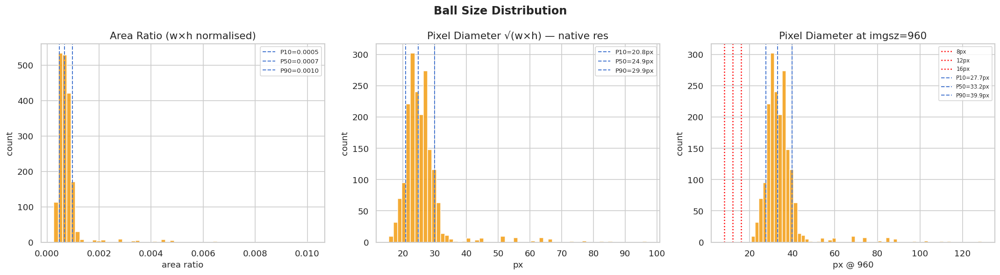


Percentile analysis:
               area_ratio      px_diam  px_diam_960
P5                  0.000       19.463       25.951
P10                 0.000       20.762       27.682
P25                 0.001       22.539       30.052
P50                 0.001       24.864       33.152
P75                 0.001       27.315       36.420
P90                 0.001       29.918       39.890
P95                 0.001       31.572       42.096
P99                 0.004       61.215       81.620


In [ ]:
def plot_ball_size_distribution(df_ann: pd.DataFrame, color=BALL_COLOR):
    """Histograms of area ratio, pixel diameter (actual + at imgsz=960), plus percentiles."""
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle("Ball Size Distribution", fontweight="bold")

    # ── Area ratio ────────────────────────────────────────────────────────
    axes[0].hist(df_ann["area_ratio"].dropna(), bins=60,
                 color=color, edgecolor="white", alpha=0.85)
    axes[0].set_title("Area Ratio (w×h normalised)")
    axes[0].set_xlabel("area ratio"); axes[0].set_ylabel("count")
    for p, v in zip([10,50,90], np.percentile(df_ann["area_ratio"].dropna(),[10,50,90])):
        axes[0].axvline(v, linestyle="--", linewidth=1.2, label=f"P{p}={v:.4f}")
    axes[0].legend(fontsize=8)

    # ── Pixel diameter at native resolution ───────────────────────────────
    axes[1].hist(df_ann["px_diam"].dropna(), bins=60,
                 color=color, edgecolor="white", alpha=0.85)
    axes[1].set_title("Pixel Diameter √(w×h) — native res")
    axes[1].set_xlabel("px"); axes[1].set_ylabel("count")
    for p, v in zip([10,50,90], np.percentile(df_ann["px_diam"].dropna(),[10,50,90])):
        axes[1].axvline(v, linestyle="--", linewidth=1.2, label=f"P{p}={v:.1f}px")
    axes[1].legend(fontsize=8)

    # ── Pixel diameter at current imgsz ───────────────────────────────────────
    axes[2].hist(df_ann[f"px_diam_{imgsz}"].dropna(), bins=60,
                 color=color, edgecolor="white", alpha=0.85)
    axes[2].set_title(f"Pixel Diameter at imgsz={imgsz}")
    axes[2].set_xlabel(f"px @ {imgsz}"); axes[2].set_ylabel("count")
    for thresh in TINY_THRESHOLDS_PX:
        axes[2].axvline(thresh, color="red", linestyle=":", linewidth=1.5,
                        label=f"{thresh}px")
    for p, v in zip([10,50,90], np.percentile(df_ann[f"px_diam_{imgsz}"].dropna(),[10,50,90])):
        axes[2].axvline(v, linestyle="--", linewidth=1.2, label=f"P{p}={v:.1f}px")
    axes[2].legend(fontsize=7)

    plt.tight_layout(); plt.show()

    # Percentile table
    pcts = [5,10,25,50,75,90,95,99]
    tbl  = pd.DataFrame({
        "area_ratio"  : np.percentile(df_ann["area_ratio"].dropna(),  pcts),
        "px_diam"     : np.percentile(df_ann["px_diam"].dropna(),     pcts),
        f"px_diam_{imgsz}" : np.percentile(df_ann[f"px_diam_{imgsz}"].dropna(), pcts),
    }, index=[f"P{p}" for p in pcts])
    print("\nPercentile analysis:")
    print(
        tbl.round(3).to_string(
            col_space=12,
            float_format=lambda x: f"{x:8.3f}"
        )
    )

plot_ball_size_distribution(df_ann)

**Comment**:

- The normalized ball area occupies only a very small fraction of the image. The distribution is strongly concentrated around low values, with a median area ratio of approximately 0.0007 and 90% of samples below 0.001. This confirms that ball detection is a small-object detection problem.

- At the original image resolution (1280x720), the ball diameter ranges mostly between 20 and 30 pixels, with a median value of approximately 25 pixels. Even before resizing, the ball occupies a limited number of pixels, highlighting the intrinsic difficulty of accurate localization.

- After resizing images to the training resolution, the effective ball diameter decreases proportionally. The red vertical lines indicate common small-object thresholds (8, 12, and 16 pixels). Every sample remains above the 16-pixel threshold, suggesting the absence of particularly challenging examples where the ball may become difficult to detect reliably.

### 6.3 · Tiny Object Breakdown

Percentage of balls below key pixel-diameter thresholds at `imgsz=640`. Rule of thumb: > 30 % below 16 px → strongly consider a higher imgsz.

  Balls <  8px @ 960 :     0 / 1857  (0.0%)
  Balls < 12px @ 960 :     0 / 1857  (0.0%)
  Balls < 16px @ 960 :     0 / 1857  (0.0%)


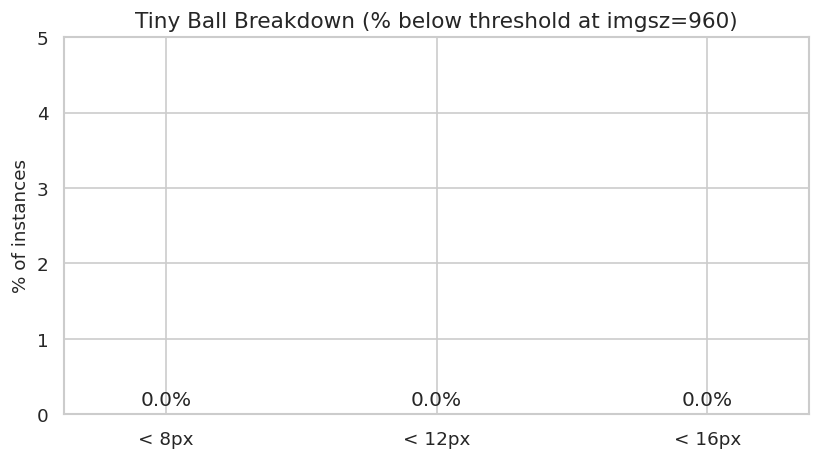

🟢 OK      : 0.0% of balls < 16px — imgsz=960 may be sufficient.


In [ ]:
def print_tiny_object_breakdown(df_ann: pd.DataFrame,
                                   thresholds=TINY_THRESHOLDS_PX):
    """Print + bar-chart % of instances below each px threshold at imgsz=960."""
    diam = df_ann[f"px_diam_{imgsz}"].dropna()
    total = len(diam)
    results = {}
    for t in thresholds:
        n    = (diam < t).sum()
        pct  = 100 * n / total
        results[f"< {t}px"] = pct
        print(f"  Balls < {t:2d}px @ {imgsz} : {n:5d} / {total}  ({pct:.1f}%)")

    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(list(results.keys()), list(results.values()),
                  color=["#e74c3c","#e67e22","#f1c40f"],
                  edgecolor="white", width=0.5)
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
    ax.set_title(f"Tiny Ball Breakdown (% below threshold at imgsz={imgsz})")
    ax.set_ylabel("% of instances")
    ax.set_ylim(0, min(100, max(results.values()) * 1.25 + 5))

    plt.tight_layout(); plt.show()

    # Recommendation
    pct_16 = results.get("< 16px", 0)
    if pct_16 > 50:
        print(f"🔴 CRITICAL: {pct_16:.1f}% of balls < 16px → higher imgsz strongly recommended.")
    elif pct_16 > 30:
        print(f"🟡 WARNING : {pct_16:.1f}% of balls < 16px → consider a higher imgsz.")
    else:
        print(f"🟢 OK      : {pct_16:.1f}% of balls < 16px — imgsz={imgsz} may be sufficient.")


print_tiny_object_breakdown(df_ann)


**Comment**:
There are no images where the ball diameter is below 16px (not even 8 px). This means that we could train the model even with imgsz = 640.

### 6.4 · Spatial Distribution Heatmap

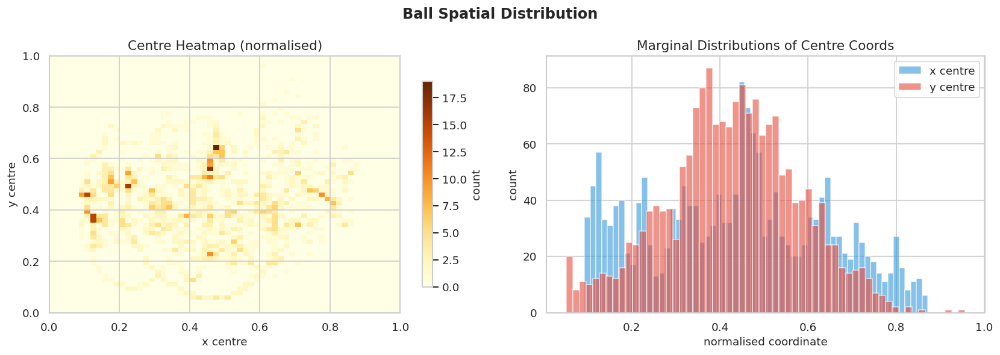

In [ ]:
def plot_spatial_heatmap(df_ann: pd.DataFrame, bins: int = 60, color=BALL_COLOR):
    """2D heatmap of normalised ball centre coordinates."""
    sub = df_ann[["xc","yc"]].dropna()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("Ball Spatial Distribution", fontweight="bold")

    # Heatmap
    h, xe, ye = np.histogram2d(sub["xc"], sub["yc"], bins=bins,
                                range=[[0,1],[0,1]])
    im = axes[0].imshow(h.T, origin="lower", extent=[0,1,0,1],
                        aspect="auto", cmap="YlOrBr")
    axes[0].set_title("Centre Heatmap (normalised)")
    axes[0].set_xlabel("x centre"); axes[0].set_ylabel("y centre")
    fig.colorbar(im, ax=axes[0], shrink=0.8, label="count")

    # Marginal distributions
    axes[1].hist(sub["xc"], bins=60, alpha=0.6, label="x centre", color="#3498db")
    axes[1].hist(sub["yc"], bins=60, alpha=0.6, label="y centre", color="#e74c3c")
    axes[1].set_title("Marginal Distributions of Centre Coords")
    axes[1].set_xlabel("normalised coordinate"); axes[1].set_ylabel("count")
    axes[1].legend()

    plt.tight_layout(); plt.show()


plot_spatial_heatmap(df_ann)

**Comment**:
These two graphs show the position of the ball in the images in the dataset. In most cases, the ball is located in the center of the image. The x-coordinates are more scattered due to the resolution of the images.

### 6.5 · Motion Blur Analysis

Laplacian variance is a proxy for sharpness. Low variance = blurry = harder to detect.

We correlate blur with ball diameter to identify the hardest samples.

Blur scores:   0%|          | 0/1857 [00:00<?, ?it/s]

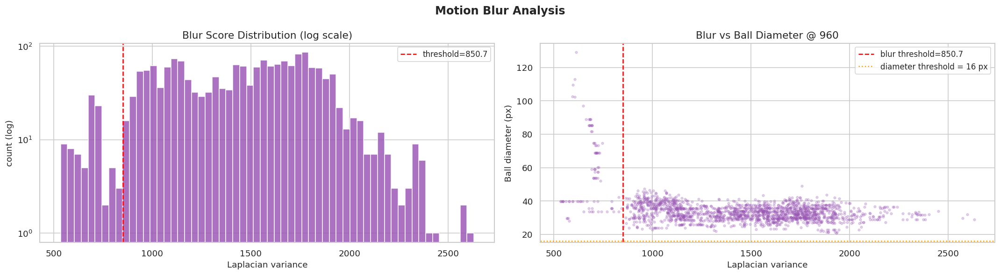

Blurry images (blur < 850.7): 93 / 1857  (5.0%)
Hardest samples (blurry + tiny < 16px): 0


In [ ]:
def compute_blur_scores(df_all: pd.DataFrame, max_images: int = 3000) -> pd.DataFrame:
    """Compute Laplacian variance (blur score) for each unique image."""
    paths = df_all["image_path"].unique()[:max_images]
    records = []
    for p in tqdm(paths, desc="Blur scores"):
        img = cv2.imread(p)
        if img is None: continue
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        records.append({"image_path": p,
                        "blur_score": float(cv2.Laplacian(gray, cv2.CV_64F).var())})
    return pd.DataFrame(records)


def plot_blur_analysis(df_ann: pd.DataFrame, df_blur: pd.DataFrame,
                        blur_thresh: float = 100.0):

    blur_thresh = np.percentile(df_blur["blur_score"], 5)

    df = df_ann.merge(df_blur, on="image_path", how="left")

    fig, axes = plt.subplots(1, 2, figsize=(18, 5))
    fig.suptitle("Motion Blur Analysis", fontweight="bold")

    # Histogram of blur scores
    axes[0].hist(df_blur["blur_score"].dropna(), bins=60,
                 color="#9b59b6", edgecolor="white", alpha=0.85, log=True)
    axes[0].axvline(blur_thresh, color="red", linestyle="--",
                    label=f"threshold={blur_thresh:.1f}")
    axes[0].set_title("Blur Score Distribution (log scale)")
    axes[0].set_xlabel("Laplacian variance"); axes[0].set_ylabel("count (log)")
    axes[0].legend(fontsize=10)

    # Blur vs ball diameter scatter
    axes[1].scatter(df["blur_score"], df[f"px_diam_{imgsz}"],
                    alpha=0.25, s=8, color="#9b59b6")
    axes[1].axvline(blur_thresh, color="red", linestyle="--", label=f"blur threshold={blur_thresh:.1f}")
    axes[1].axhline(16, color="orange", linestyle=":", label="diameter threshold = 16 px")
    axes[1].set_title(f"Blur vs Ball Diameter @ {imgsz}")
    axes[1].set_xlabel("Laplacian variance"); axes[1].set_ylabel("Ball diameter (px)")
    axes[1].legend(fontsize=10)

    plt.tight_layout(); plt.show()

    blurry_imgs = (df_blur["blur_score"] < blur_thresh).sum()
    print(f"Blurry images (blur < {blur_thresh:.1f}): "
          f"{blurry_imgs} / {len(df_blur)}  "
          f"({100*blurry_imgs/max(len(df_blur),1):.1f}%)")
    hard = df[(df["blur_score"] < blur_thresh) & (df[f"px_diam_{imgsz}"] < 16)]
    print(f"Hardest samples (blurry + tiny < 16px): {len(hard)}")
    if not hard.empty:
        print("Top 5 hardest images:")
        print(hard.nsmallest(5,"blur_score")[["image_path","blur_score",f"px_diam_{imgsz}"]]
              .to_string(index=False))

df_blur = compute_blur_scores(df_all)
plot_blur_analysis(df_ann, df_blur)

**Comment**:

The histogram shows the distribution of Laplacian variance values across the dataset. The red dashed line indicates the 5th percentile, separating the least sharp images from the remaining samples. This threshold is used to identify potentially blurred frames that may increase the difficulty of ball detection.

The scatter plot shows the blur score versus ball diameter. Each point corresponds to an image in the dataset. Lower blur scores indicate less sharp images, while smaller diameters correspond to harder detection targets. The lower-left area of the plot therefore represents the most challenging samples, combining small object size and motion blur.

### 6.6 · Occlusion Analysis

Occlusion:   0%|          | 0/1857 [00:00<?, ?it/s]

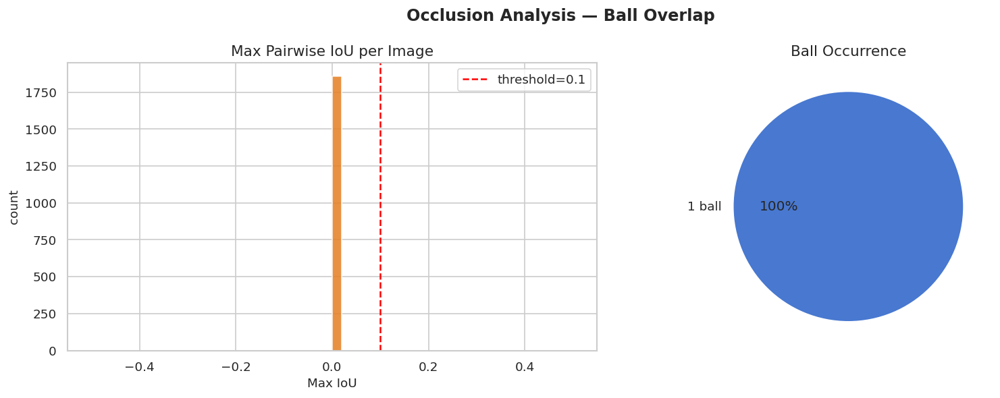

Images with more than 1 ball: 0 (0.0%)
Crowded frames (IoU ≥ 0.1): 0 (0.0%)


In [ ]:
def iou_pair(b1, b2):
    x1min = b1[0]-b1[2]/2; x1max = b1[0]+b1[2]/2
    y1min = b1[1]-b1[3]/2; y1max = b1[1]+b1[3]/2
    x2min = b2[0]-b2[2]/2; x2max = b2[0]+b2[2]/2
    y2min = b2[1]-b2[3]/2; y2max = b2[1]+b2[3]/2
    ix = max(0, min(x1max,x2max)-max(x1min,x2min))
    iy = max(0, min(y1max,y2max)-max(y1min,y2min))
    inter = ix*iy
    union = b1[2]*b1[3] + b2[2]*b2[3] - inter
    return inter/union if union > 0 else 0.0


def compute_occlusion(df_ann: pd.DataFrame, max_images: int = 2000) -> pd.DataFrame:
    """Per-image max pairwise IoU (proxy for occlusion / crowding)."""
    records = []
    for img_path in tqdm(df_ann["image_path"].unique()[:max_images], desc="Occlusion"):
        sub   = df_ann[df_ann["image_path"]==img_path][["xc","yc","bw","bh"]].dropna()
        boxes = sub.values.tolist()
        n     = len(boxes)
        max_iou = 0.0
        for i in range(n):
            for j in range(i+1,n):
                max_iou = max(max_iou, iou_pair(boxes[i], boxes[j]))
        records.append({"image_path": img_path, "n_balls": n, "max_iou": max_iou})
    return pd.DataFrame(records)


def plot_occlusion(df_occ: pd.DataFrame, iou_thresh: float = 0.1):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("Occlusion Analysis — Ball Overlap", fontweight="bold")

    axes[0].hist(df_occ["max_iou"], bins=50, color="#e67e22", edgecolor="white", alpha=0.85)
    axes[0].axvline(iou_thresh, color="red", linestyle="--",
                    label=f"threshold={iou_thresh}")
    axes[0].set_title("Max Pairwise IoU per Image")
    axes[0].set_xlabel("Max IoU"); axes[0].set_ylabel("count")
    axes[0].legend()

    axes[1].pie(
        [len(df_occ)],
        labels=["1 ball"],
        autopct="%1.0f%%"
    )

    axes[1].set_title("Ball Occurrence")

    plt.tight_layout(); plt.show()

    crowded = (df_occ["max_iou"] >= iou_thresh).sum()
    multi   = (df_occ["n_balls"] > 1).sum()
    print(f"Images with more than 1 ball: {multi} ({100*multi/max(len(df_occ),1):.1f}%)")
    print(f"Crowded frames (IoU ≥ {iou_thresh}): {crowded} ({100*crowded/max(len(df_occ),1):.1f}%)")


df_occlusion = compute_occlusion(df_ann)
plot_occlusion(df_occlusion)

**Comment**:
Each image contains a single basketball annotation and no overlapping bounding boxes are present. Consequently, the dataset represents a clean single-object detection problem, free from ambiguities caused by multiple target instances or annotation overlaps.

### 6.7 · Edge Proximity Analysis

Balls near image borders are often truncated. This affects how YOLO regresses the box and whether the annotation is complete.

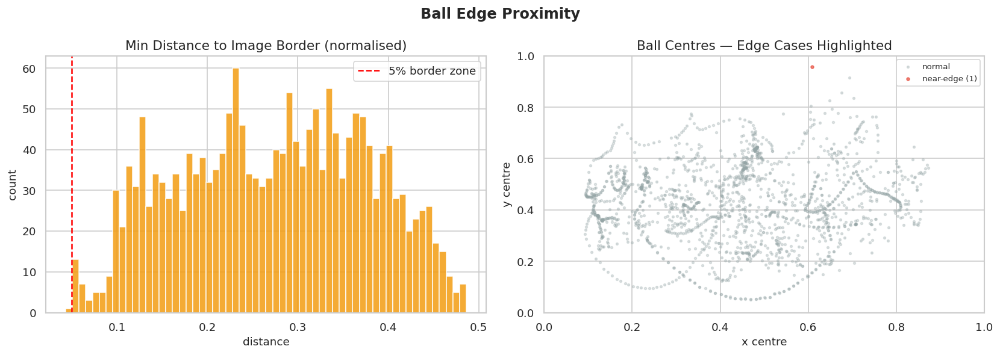

Near-edge balls (within 5% of border): 1 (0.1%)


In [ ]:
def compute_edge_proximity(df_ann: pd.DataFrame) -> pd.DataFrame:
    """Compute min distance from ball centre to any image border (normalised 0-0.5)."""
    df = df_ann.copy()
    df["dist_left"]   = df["xc"]
    df["dist_right"]  = 1.0 - df["xc"]
    df["dist_top"]    = df["yc"]
    df["dist_bottom"] = 1.0 - df["yc"]
    df["min_edge_dist"] = df[["dist_left","dist_right","dist_top","dist_bottom"]].min(axis=1)
    df["near_edge"]   = df["min_edge_dist"] < 0.05   # within 5% of border
    return df


def plot_edge_proximity(df_ep: pd.DataFrame, color=BALL_COLOR):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("Ball Edge Proximity", fontweight="bold")

    axes[0].hist(df_ep["min_edge_dist"].dropna(), bins=60,
                 color=color, edgecolor="white", alpha=0.85)
    axes[0].axvline(0.05, color="red", linestyle="--", label="5% border zone")
    axes[0].set_title("Min Distance to Image Border (normalised)")
    axes[0].set_xlabel("distance"); axes[0].set_ylabel("count")
    axes[0].legend()

    # Scatter of centres, colour = near edge
    near = df_ep[df_ep["near_edge"]]
    far  = df_ep[~df_ep["near_edge"]]
    axes[1].scatter(far["xc"],  far["yc"],  s=5, alpha=0.3, color="#95a5a6", label="normal")
    axes[1].scatter(near["xc"], near["yc"], s=8, alpha=0.7, color="#e74c3c", label=f"near-edge ({len(near)})")
    axes[1].set_xlim(0,1); axes[1].set_ylim(0,1)
    axes[1].set_title("Ball Centres — Edge Cases Highlighted")
    axes[1].set_xlabel("x centre"); axes[1].set_ylabel("y centre")
    axes[1].legend(fontsize=8)

    plt.tight_layout(); plt.show()

    pct = 100*df_ep["near_edge"].mean()
    print(f"Near-edge balls (within 5% of border): {df_ep['near_edge'].sum()} ({pct:.1f}%)")


df_edge = compute_edge_proximity(df_ann)
plot_edge_proximity(df_edge)

**Comment**:

The first graph shows that in very few images (0.1%) , the ball is located near the edges of the frame. This means that, in most cases, the ball is not truncated.

The second image is very similar to the one representing the spatial distribution of the ball (section 6.4). In this case, we consider the center of the ball.

### 6.8 · Visibility Categories

Heuristic classification of each instance into three visibility categories based on blur score, bbox proximity to edge, and intra-image IoU.

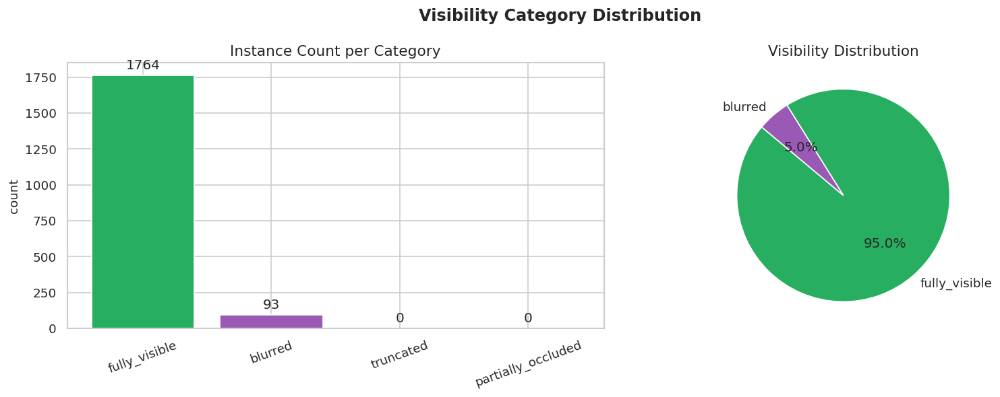

fully_visible            :  1764  (95.0%)
blurred                  :    93  (5.0%)
truncated                :     0  (0.0%)
partially_occluded       :     0  (0.0%)


In [ ]:
def classify_visibility(df_ann: pd.DataFrame,
                          df_blur: pd.DataFrame,
                          df_occ: pd.DataFrame,
                          blur_thresh: float = 850.7,
                          edge_thresh: float = 0.05,
                          iou_thresh:  float = 0.1) -> pd.DataFrame:
    """
    Tag each instance with a visibility category:
      fully_visible / truncated / blurred / partially_occluded
    Priority: occluded > blurred > truncated > fully_visible
    """
    df = df_ann.copy()

    # Merge per-image signals
    df = df.merge(df_blur[["image_path","blur_score"]], on="image_path", how="left")
    df = df.merge(df_occ[["image_path","max_iou"]],     on="image_path", how="left")

    # Edge proximity flag
    df["dist_left"]   = df["xc"]
    df["dist_right"]  = 1 - df["xc"]
    df["dist_top"]    = df["yc"]
    df["dist_bottom"] = 1 - df["yc"]
    df["min_edge"]    = df[["dist_left","dist_right","dist_top","dist_bottom"]].min(axis=1)

    df["truncated"]  = df["min_edge"] < edge_thresh
    df["blurred"]    = df["blur_score"] < blur_thresh
    df["occluded"]   = df["max_iou"] >= iou_thresh

    def label(row):
        if row["occluded"]: return "partially_occluded"
        if row["blurred"]:  return "blurred"
        if row["truncated"]:return "truncated"
        return "fully_visible"

    df["visibility"] = df.apply(label, axis=1)
    return df


def plot_visibility(df_vis: pd.DataFrame):
    all_categories = [
        "fully_visible",
        "blurred",
        "truncated",
        "partially_occluded"
    ]
    counts = df_vis["visibility"].value_counts().reindex(all_categories, fill_value=0)
    colors = {"fully_visible":"#27ae60","blurred":"#9b59b6",
              "truncated":"#e67e22","partially_occluded":"#e74c3c"}
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("Visibility Category Distribution", fontweight="bold")

    bars = axes[0].bar(counts.index, counts.values,
                       color=[colors.get(k,"#7f8c8d") for k in counts.index],
                       edgecolor="white")
    axes[0].bar_label(bars, fmt="%d", padding=3)
    axes[0].set_title("Instance Count per Category")
    axes[0].set_ylabel("count")
    axes[0].tick_params(axis="x", rotation=20)

    pie_counts = counts[counts > 0]
    axes[1].pie(pie_counts.values, labels=pie_counts.index,
                colors=[colors.get(k,"#7f8c8d") for k in pie_counts.index],
                autopct="%1.1f%%", startangle=140)
    axes[1].set_title("Visibility Distribution")

    plt.tight_layout(); plt.show()

    total = len(df_vis)
    for cat, cnt in counts.items():
        print(f"{cat:25s}: {cnt:5d}  ({100*cnt/total:.1f}%)")


df_vis = classify_visibility(df_ann, df_blur, df_occlusion)
plot_visibility(df_vis)

**Comment**:
Out of the 1857 total images, just 186 (10.0%) are blurred, 0 are truncated (the one found in the previous section is classified as blurred) and 0 are partially occluded. This indicates that the dataset is very clean.

### 6.9 · False Positive Risk Analysis

Estimate the density of circular-like blobs in background crops. Hough blob density relative to ball size is a sign of confusing backgrounds.

FP risk:   0%|          | 0/200 [00:00<?, ?it/s]

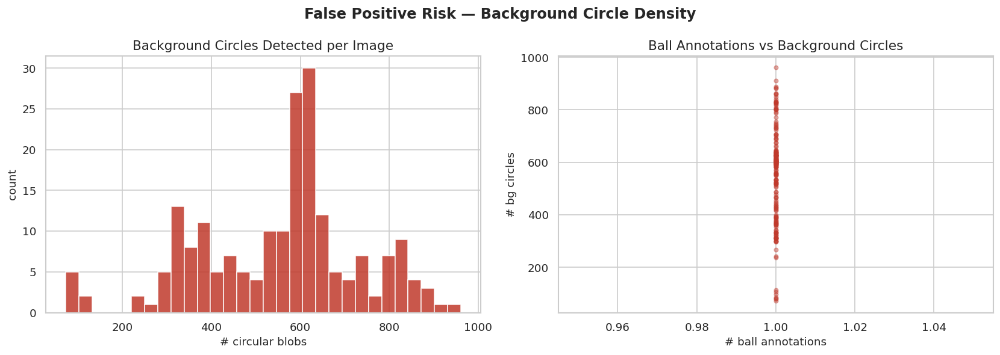

High FP-risk images (top 10% bg circles): 20
                                                                                                                                            image_path  n_bg_circles
       /content/drive/MyDrive/DeepLearningProject/datasets/ball_1858.yolo26/train/images/Wolves@Nuggets_Start_mp4-0084_jpg.rf.lQnGIGPwVdNw10kuUgba.jpg           961
/content/drive/MyDrive/DeepLearningProject/datasets/ball_1858.yolo26/train/images/Nuggets@Wolves_ballhugLayup_mp4-0011_jpg.rf.9kCgAFVITUp6dmbBYj3M.jpg           912
/content/drive/MyDrive/DeepLearningProject/datasets/ball_1858.yolo26/train/images/Nuggets@Wolves_ballhugLayup_mp4-0015_jpg.rf.848MgByRT4VO5ppFpZVu.jpg           888
/content/drive/MyDrive/DeepLearningProject/datasets/ball_1858.yolo26/train/images/Nuggets@Wolves_ballhugLayup_mp4-0010_jpg.rf.vTzv9MbDsiAlFaPOBnFo.jpg           883
/content/drive/MyDrive/DeepLearningProject/datasets/ball_1858.yolo26/train/images/Nuggets@Wolves_ballhugLayup_mp4-0086_jpg.rf.h7hM

In [ ]:
def compute_fp_risk(df_ann: pd.DataFrame,
                      df_blur: pd.DataFrame,
                      n_images: int = 200,
                      seed: int = 42) -> pd.DataFrame:
    """
    For a sample of annotated images, detect circular Hough blobs in the background
    (outside annotated bboxes) as a false-positive risk proxy.
    Returns a DataFrame with columns: image_path, n_ball_annotations, n_bg_circles.
    """
    rng    = random.Random(seed)
    sample = rng.sample(df_ann["image_path"].unique().tolist(),
                        min(n_images, df_ann["image_path"].nunique()))
    records = []

    for img_path in tqdm(sample, desc="FP risk"):
        img = cv2.imread(img_path)
        if img is None: continue
        h, w = img.shape[:2]
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        blur = cv2.GaussianBlur(gray, (9,9), 2)

        # Hough circles — search in size range matching tiny balls
        circles = cv2.HoughCircles(
            blur, cv2.HOUGH_GRADIENT, dp=1.2,
            minDist=max(5, int(w*0.01)),
            param1=80, param2=25,
            minRadius=2, maxRadius=max(10, int(w*0.04))
        )
        n_circles = 0 if circles is None else circles.shape[1]

        ann_boxes = df_ann[df_ann["image_path"]==img_path][["xc","yc","bw","bh"]].dropna()
        n_ann = len(ann_boxes)

        records.append({"image_path": img_path,
                        "n_ball_annotations": n_ann,
                        "n_bg_circles": n_circles})

    return pd.DataFrame(records)


def plot_fp_risk(df_fp: pd.DataFrame):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("False Positive Risk — Background Circle Density", fontweight="bold")

    axes[0].hist(df_fp["n_bg_circles"], bins=30, color="#c0392b",
                 edgecolor="white", alpha=0.85)
    axes[0].set_title("Background Circles Detected per Image")
    axes[0].set_xlabel("# circular blobs"); axes[0].set_ylabel("count")

    axes[1].scatter(df_fp["n_ball_annotations"], df_fp["n_bg_circles"],
                    alpha=0.4, s=15, color="#c0392b")
    axes[1].set_title("Ball Annotations vs Background Circles")
    axes[1].set_xlabel("# ball annotations"); axes[1].set_ylabel("# bg circles")

    plt.tight_layout(); plt.show()

    high_fp = df_fp[df_fp["n_bg_circles"] > df_fp["n_bg_circles"].quantile(0.9)]
    print(f"High FP-risk images (top 10% bg circles): {len(high_fp)}")

    if not high_fp.empty:
        print(high_fp.nlargest(5,"n_bg_circles")[["image_path","n_bg_circles"]].to_string(index=False))


df_fp = compute_fp_risk(df_ann, df_blur)
plot_fp_risk(df_fp)

**Comment**:
Although there are hundreds of circles in each image, only one of them is labeled as the ball. This means the model is always able to identify the correct subject.

### 6.10 · Frame Redundancy & Video Leakage Risk

Near-duplicate frames inflate training set size without adding diversity, and if they span splits they cause data leakage.

In [ ]:
from collections import defaultdict
import pandas as pd
from tqdm import tqdm

def detect_frame_redundancy(df_all: pd.DataFrame,
                            hash_size: int = 8,
                            max_diff: int = 5,
                            max_images: int = 3000) -> pd.DataFrame:
    """
    Compute pHash for each image, find near-duplicate pairs (Hamming <= max_diff).

    Outputs:
      - Total photos
      - Unique photos (exact duplicates collapsed)
      - Duplicate photos (copies only, Hamming = 0)
      - Duplicate groups
      - Pair statistics for each Hamming distance

    Returns:
      DataFrame containing all duplicate pairs.
    """

    if not _IMAGEHASH_OK:
        print("⚠️ imagehash not available — install with: pip install imagehash Pillow")
        return pd.DataFrame()

    # ------------------------------------------------------------
    # Compute perceptual hashes
    # ------------------------------------------------------------
    img_paths = df_all["image_path"].unique()[:max_images]

    hashes = {}
    for p in tqdm(img_paths, desc="Perceptual hashing"):
        try:
            hashes[p] = imagehash.phash(PILImage.open(p), hash_size=hash_size)
        except Exception:
            pass

    path_to_split = (
        df_all.drop_duplicates("image_path")
              .set_index("image_path")["split"]
    )

    # ------------------------------------------------------------
    # Compute all pairs
    # ------------------------------------------------------------
    paths = list(hashes.keys())
    pairs = []

    for i in range(len(paths)):
        for j in range(i + 1, len(paths)):
            d = hashes[paths[i]] - hashes[paths[j]]

            if d <= max_diff:
                sa = path_to_split.get(paths[i], "?")
                sb = path_to_split.get(paths[j], "?")

                pairs.append({
                    "img_a": paths[i],
                    "img_b": paths[j],
                    "hamming": d,
                    "split_a": sa,
                    "split_b": sb,
                    "is_leakage": sa != sb
                })

    df_pairs = pd.DataFrame(pairs)

    # ------------------------------------------------------------
    # Dataset statistics
    # ------------------------------------------------------------
    total_photos = len(hashes)

    print(f"\nImages hashed         : {total_photos:,}")
    print(f"Near-duplicate pairs  : {len(df_pairs):,}")

    # ------------------------------------------------------------
    # Exact duplicates (Hamming = 0)
    # ------------------------------------------------------------
    graph = defaultdict(set)

    if not df_pairs.empty:
        exact_pairs = df_pairs[df_pairs["hamming"] == 0]

        for _, row in exact_pairs.iterrows():
            a = row["img_a"]
            b = row["img_b"]
            graph[a].add(b)
            graph[b].add(a)

    visited = set()
    duplicate_groups = 0
    duplicate_copies = 0

    for node in graph:

        if node in visited:
            continue

        stack = [node]
        component = set()

        while stack:
            current = stack.pop()

            if current in visited:
                continue

            visited.add(current)
            component.add(current)

            for neigh in graph[current]:
                if neigh not in visited:
                    stack.append(neigh)

        duplicate_groups += 1
        duplicate_copies += len(component) - 1

    unique_photos = total_photos - duplicate_copies

    # Sanity check
    assert unique_photos + duplicate_copies == total_photos

    print("\n========== DATASET STATISTICS ==========")
    print(f"Total photos       : {total_photos:,}")
    print(f"Unique photos      : {unique_photos:,}")
    print(f"Duplicate photos   : {duplicate_copies:,}")
    print(f"Duplicate groups   : {duplicate_groups:,}")

    if duplicate_groups > 0:
        avg_group_size = (duplicate_copies + duplicate_groups) / duplicate_groups
        print(f"Average group size : {avg_group_size:.2f}")

    # ------------------------------------------------------------
    # Hamming statistics
    # ------------------------------------------------------------
    if not df_pairs.empty:

        print("\nDuplicate pairs by Hamming distance:")

        stats = []

        for h in range(max_diff + 1):

            subset = df_pairs[df_pairs["hamming"] == h]

            stats.append({
                "hamming": h,
                "pairs": len(subset),
                "unique_images": len(
                    set(subset["img_a"]).union(set(subset["img_b"]))
                )
            })

        print(pd.DataFrame(stats).to_string(index=False))

        leakage = df_pairs["is_leakage"].sum()
        print(f"\nCross-split leakage pairs : {leakage:,}")

    else:
        print("\n✅ No near-duplicate frames found.")

    return df_pairs


# Run
df_redundancy = detect_frame_redundancy(df_all)

Perceptual hashing: 100%|██████████| 1857/1857 [00:32<00:00, 56.84it/s]



Images hashed         : 1,857
Near-duplicate pairs  : 23,473

========== DATASET STATISTICS ==========
Total photos       : 1,857
Unique photos      : 942
Duplicate photos   : 915
Duplicate groups   : 316
Average group size : 3.90

Duplicate pairs by Hamming distance:
 hamming  pairs  unique_images
       0   4392           1231
       1      0              0
       2   8087           1640
       3      0              0
       4  10994           1754
       5      0              0

Cross-split leakage pairs : 7,834


### 6.11 · Image Quality Metrics

Image quality:   0%|          | 0/1857 [00:00<?, ?it/s]

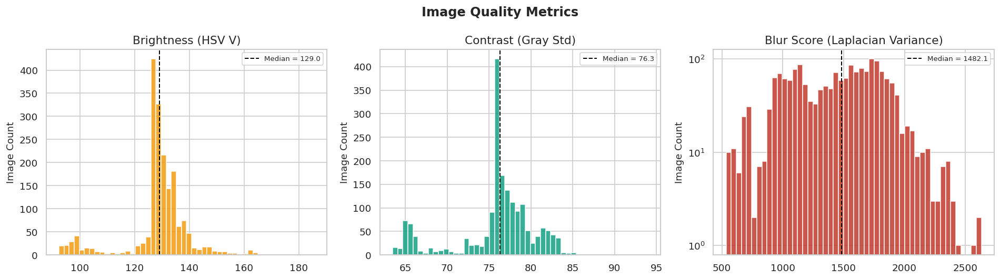


Dataset Resolution
------------------------------------------------------------
Resolution : 1280 × 720 px
Megapixels : 0.922 MP
Images     : 1,857
Uniform resolution across dataset : YES

Quality Statistics
------------------------------------------------------------
       brightness  contrast  blur_score
count     1857.00   1857.00     1857.00
mean       128.50     75.87     1443.95
std         11.33      4.75      381.12
min         92.33     63.47      534.55
25%        126.86     75.47     1124.90
50%        129.04     76.30     1482.10
75%        133.48     78.57     1737.49
max        185.62     93.95     2631.45

Potential Quality Issues
------------------------------------------------------------
Dark images (brightness < 40) : 0
Low contrast (std < 20)       : 0
Blurry images (blur < 50)     : 0


In [ ]:
def compute_image_quality(df_all: pd.DataFrame,
                             max_images: int = 3000) -> pd.DataFrame:
    """Brightness, contrast (std of gray), resolution, and blur per image."""
    paths = df_all["image_path"].unique()[:max_images]
    records = []
    for p in tqdm(paths, desc="Image quality"):
        img = cv2.imread(p)
        if img is None: continue
        h, w = img.shape[:2]
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        hsv  = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        records.append({
            "image_path" : p,
            "width"      : w,
            "height"     : h,
            "megapixels" : w*h/1e6,
            "brightness" : float(hsv[:,:,2].mean()),
            "contrast"   : float(gray.std()),
            "blur_score" : float(cv2.Laplacian(gray, cv2.CV_64F).var()),
        })
    return pd.DataFrame(records)


def plot_image_quality(df_iq: pd.DataFrame):

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    fig.suptitle("Image Quality Metrics", fontweight="bold")

    metrics = [
        ("brightness", "Brightness (HSV V)", "#f39c12", False),
        ("contrast",   "Contrast (Gray Std)", "#16a085", False),
        ("blur_score", "Blur Score (Laplacian Variance)", "#c0392b", True),
    ]

    for ax, (col, title, color, log_scale) in zip(axes, metrics):

        data = df_iq[col].dropna()

        ax.hist(
            data,
            bins=50,
            color=color,
            edgecolor="white",
            alpha=0.85,
            log=log_scale
        )

        median = data.median()

        ax.axvline(
            median,
            color="black",
            linestyle="--",
            linewidth=1.2,
            label=f"Median = {median:.1f}"
        )

        ax.set_title(title)
        ax.set_ylabel("Image Count")
        ax.legend(fontsize=8)

    plt.tight_layout()
    plt.show()

    # ---------------------------------------------------------
    # Dataset resolution summary
    # ---------------------------------------------------------

    width = int(df_iq["width"].iloc[0])
    height = int(df_iq["height"].iloc[0])
    megapixels = df_iq["megapixels"].iloc[0]

    print("\nDataset Resolution")
    print("-" * 60)
    print(f"Resolution : {width} × {height} px")
    print(f"Megapixels : {megapixels:.3f} MP")
    print(f"Images     : {len(df_iq):,}")

    # Sanity check
    uniform_res = (
        df_iq["width"].nunique() == 1
        and
        df_iq["height"].nunique() == 1
    )

    print(
        f"Uniform resolution across dataset : "
        f"{'YES' if uniform_res else 'NO'}"
    )

    # ---------------------------------------------------------
    # Quality statistics
    # ---------------------------------------------------------

    print("\nQuality Statistics")
    print("-" * 60)

    print(
        df_iq[
            [
                "brightness",
                "contrast",
                "blur_score"
            ]
        ]
        .describe()
        .round(2)
        .to_string()
    )

    dark = (df_iq["brightness"] < 40).sum()
    low_contrast = (df_iq["contrast"] < 20).sum()
    blurry = (df_iq["blur_score"] < 50).sum()

    print("\nPotential Quality Issues")
    print("-" * 60)
    print(f"Dark images (brightness < 40) : {dark:,}")
    print(f"Low contrast (std < 20)       : {low_contrast:,}")
    print(f"Blurry images (blur < 50)     : {blurry:,}")


df_quality = compute_image_quality(df_all)
plot_image_quality(df_quality)

**Comment**:

- The brightness distribution is centered around a median value of 129, indicating generally well-exposed images. Only a small number of samples fall into darker or brighter extremes, suggesting consistent illumination conditions across the dataset.

- The contrast distribution is relatively narrow, with a median value of 76.3. No images fall below the low-contrast threshold, indicating that visual details remain sufficiently distinguishable throughout the dataset.

- Blur scores are concentrated around a median value of approximately 1482, with no images below the predefined blur threshold. This suggests that the dataset contains very few severely blurred frames and generally preserves adequate image sharpness.

Overall the dataset exhibits consistent image quality, with stable brightness, sufficient contrast, and limited motion blur. No major quality issues were identified, providing favorable conditions for training and evaluating ball detection models.

### 6.12 · Annotated Sample Grid

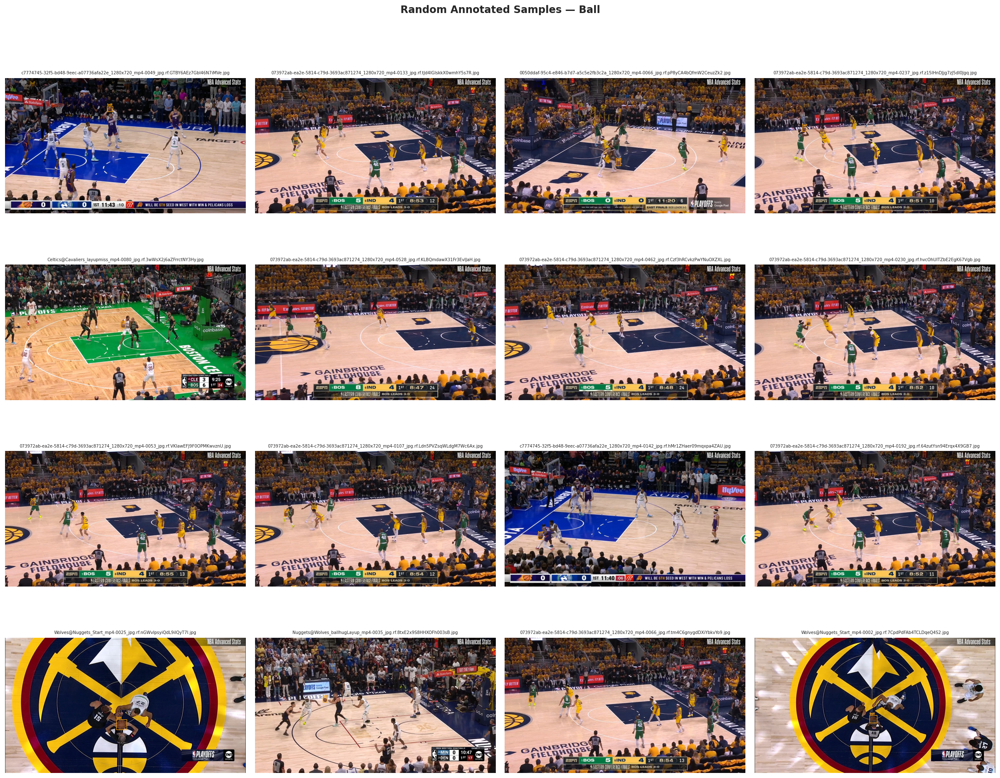

In [ ]:
def draw_ball_boxes(img_bgr: np.ndarray,
                     boxes_norm: list,
                     color_rgb=(243,156,18),
                     label: str = "ball") -> np.ndarray:
    """Draw YOLO normalised bboxes on image, return RGB."""
    img = img_bgr.copy()
    h, w = img.shape[:2]
    color_bgr = color_rgb[::-1]
    for (xc, yc, bw, bh) in boxes_norm:
        x1 = int((xc-bw/2)*w); y1 = int((yc-bh/2)*h)
        x2 = int((xc+bw/2)*w); y2 = int((yc+bh/2)*h)
        cv2.rectangle(img, (x1,y1), (x2,y2), color_bgr, 2)
        cv2.putText(img, label, (x1, max(y1-5,10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color_bgr, 2)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def show_ball_grid(df_ann: pd.DataFrame,
                   df_quality: pd.DataFrame = None,
                   n: int = 16, ncols: int = 4,
                   title: str = "Random Ball Samples",
                   filter_paths=None, seed: int = 42):
    """Display a grid of annotated images. Pass filter_paths to show edge cases."""
    all_paths = df_ann["image_path"].unique().tolist()
    if filter_paths is not None:
        pool = [p for p in filter_paths if p in set(all_paths)]
    else:
        pool = all_paths
    rng    = random.Random(seed)
    sample = rng.sample(pool, min(n, len(pool)))

    nrows = int(np.ceil(len(sample) / ncols))
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(5*ncols, 4*nrows))
    fig.suptitle(title, fontweight="bold", y=1.01)
    axes = np.array(axes).flatten()

    for ax, img_path in zip(axes, sample):
        img = cv2.imread(img_path)
        if img is None: ax.axis("off"); continue
        sub   = df_ann[df_ann["image_path"]==img_path][["xc","yc","bw","bh"]].dropna()
        boxes = sub.values.tolist()
        rgb   = draw_ball_boxes(img, boxes)
        ax.imshow(rgb)
        ax.set_title(Path(img_path).name, fontsize=6)
        ax.axis("off")

    for ax in axes[len(sample):]:
        ax.axis("off")
    plt.tight_layout(); plt.show()


# Random annotated samples
show_ball_grid(df_ann, n=16, ncols=4, title="Random Annotated Samples — Ball")

# Tiny balls (< 12 px at 640)
tiny_paths = df_ann[df_ann[f"px_diam_{imgsz}"] < 12]["image_path"].unique().tolist()
if tiny_paths:
    show_ball_grid(df_ann, n=12, ncols=4,
                   title=f"Tiny Balls < 12px @ {imgsz}",
                   filter_paths=tiny_paths)

# Hardest (blurry + tiny)
hard_paths = df_ann[
    (df_ann[f"px_diam_{imgsz}"] < 16) &
    (df_ann["image_path"].isin(df_blur[df_blur["blur_score"] < 100]["image_path"]))
]["image_path"].unique().tolist()
if hard_paths:
    show_ball_grid(df_ann, n=12, ncols=4,
                   title="Hardest Examples — Tiny & Blurry",
                   filter_paths=hard_paths)

### 6.13 · Analysis Summary & Training Recommendations



Review these findings before starting Section 7:

| Signal | Threshold | Action |
|--------|-----------|--------|
| > 30% balls < 16 px @ 640 | — | Use a higher `imgsz` |
| > 50% blurry images | blur < 100 | Add motion-blur augmentation (`blur_limit`) |
| > 10% near-edge balls | dist < 5% | Enable `copy_paste` augmentation |
| High bg circle density | top 10% | Mine hard negatives from those images |
| Cross-split duplicates | any | Remove or quarantine leaked images |
| Many partially-occluded | > 20% | Lower NMS `iou_thresh` at inference |

## 7 · TRAINING

### 7.1 · Look for checkpoints

In [ ]:
# ── Check for interrupted run ──────────────────────────────────────────────
_last_ckpt = (Path("/content/drive/MyDrive/DeepLearningProject") / (HYPERPARAMS["project"]) / HYPERPARAMS["name"] / "checkpoints" / "last.pt")
_resume    = _last_ckpt.exists()
if _resume:
    print(f"Interrupted run detected — resuming from {_last_ckpt}")
    model = YOLO(str(_last_ckpt))   # reload from checkpoint

### 7.2 · Callback that saves on Drive the checkpoints and the final results
This way, if the connection drops during a training session, I can pick up where I left off.
This section creates and adds callbacks to the model that take the partial saves automatically created by YOLO and save them to the corresponding folder on the drive.

#### 7.2.1 ·  Defining directories

In [ ]:
# ── Mount Drive (uncomment if needed) ─────────────────
# drive.mount('/content/drive')

# ── Source directories ────────────────────────────────
RUN_DIR = Path("/content/runs/detect") / HYPERPARAMS["project"] / HYPERPARAMS["name"]
WEIGHTS_DIR = RUN_DIR / "weights"

# ── Dove salvare su Drive checkpoints ─────────────────────────────
DRIVE_SAVE_DIR = (Path("/content/drive/MyDrive/DeepLearningProject" ) /  HYPERPARAMS["project"] /  HYPERPARAMS["name"]  / "checkpoints")
DRIVE_SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ── Destination directory on Google Drive completed ────────────
MODEL_DRIVE_SAVE_DIR = (
    Path("/content/drive/MyDrive/DeepLearningProject")
    / HYPERPARAMS["project"]
    / HYPERPARAMS["name"]
    / "completed"
)
METRICS_DRIVE_SAVE_DIR= MODEL_DRIVE_SAVE_DIR / "metrics"

MODEL_DRIVE_SAVE_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DRIVE_SAVE_DIR.mkdir(parents=True, exist_ok=True)

#### 7.2.2 ·  Setting up the Drive and Backups

> Add blockquote



In [ ]:
#
#        GOOGLE DRIVE BACKUP SETUP (SAFE MODE)
#

# ── Backup function ────────────────────────────────────
def backup_checkpoints(run_dir: Path, drive_dir: Path):
    files = ["best.pt", "last.pt", "results.csv"]

    for f in files:
        # results.csv is one directory level up from the weights folder
        if f == "results.csv":
            src = run_dir.parent / f
        else:
            src = run_dir / f

        if src.exists():
            dst = drive_dir / f
            shutil.copy2(src, dst)
            print(f"✅ Backup: {f} → Drive")
        else:
            print(f"⚠️ Missing: {f}")

# ── Callback Ultralytics ──────────────────────────────
def on_train_epoch_end(trainer):
    epoch = trainer.epoch

    # salva ogni 10 epoche (modificabile)
    if epoch % 10 == 0 and epoch > 0:
        print(f"\nBackup checkpoint epoch {epoch}")
        try:
            backup_checkpoints(WEIGHTS_DIR, DRIVE_SAVE_DIR)
        except Exception as e:
            print("❌ Backup error:", e)

# ── Registra callback ──────────────────────────────────
model.add_callback("on_train_epoch_end", on_train_epoch_end)

print("✅ Auto-backup su Drive attivato")

✔ Auto-backup su Drive attivato


#### 7.2.3 · Final Backup

In [ ]:
#
#      GOOGLE DRIVE BACKUP AFTER TRAIN COMPLETION
#

# ── Backup function ───────────────────────────────────
def backup_training_results(run_dir: Path, drive_model_dir: Path, drive_metrics_dir: Path):
    """
    Backup:
      - from weights/: ONLY best.pt
      - from run_dir/: everything EXCEPT weights/
    """

    weights_dir = run_dir / "weights"


    # 1) Weights (filtered)

    if weights_dir.exists():
      for fname in ["best.pt"]:
          src = weights_dir / fname

          if src.exists():

            # ── Separate destinations ─────────────────────
            if fname == "best.pt":
                dst_model = drive_model_dir / "best.pt"

            shutil.copy2(src, dst_model)
            print(f"✅ Copied from weights: {fname}")

          else:
            print(f"⚠️ Missing in weights: {fname}")
    else:
        print(f"❌ Weights directory not found: {weights_dir}")


    # 2) Full run_dir backup excluding weights/

    for path in run_dir.rglob("*"):
        # skip weights folder entirely
        if weights_dir in path.parents or path == weights_dir:
            continue

        if path.is_file():
            relative_path = path.relative_to(run_dir)
            dst = drive_metrics_dir / relative_path
            dst.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(path, dst)
            print(f"✅ Copied: {relative_path}")

    print("\n✅ Backup completed successfully!")


# ── Callback: executes ONLY when training ends OK ────
def on_train_end(trainer):
    print("\nTraining completed — starting Drive backup...")

    try:
        backup_training_results(RUN_DIR, MODEL_DRIVE_SAVE_DIR, METRICS_DRIVE_SAVE_DIR)
    except Exception as e:
        print(f"❌ Backup error: {e}")


# ── Register callback ─────────────────────────────────
model.add_callback("on_train_end", on_train_end)

print("✅ Auto-backup on successful training completion activated")

✔ Auto-backup on successful training completion activated


### 7.3 · Loading dataset to local environment
To increase training performance, the dataset is loaded locally (on the machine that performs the training)

In [ ]:
logger = logging.getLogger(__name__)

def ensure_local_dataset_auto_zip(
    drive_base_path: str,
    dataset_name: str,
    local_base_path: str = "/content/dataset",
    force_copy: bool = False
) -> str:
    """
    Checks for a zipped dataset on Drive, creates it if missing,
    and extracts it to the local Colab SSD for maximum speed.
    """
    drive_folder = Path(drive_base_path) / dataset_name
    drive_zip = Path(drive_base_path) / f"{dataset_name}.zip"

    local_path = Path(local_base_path)
    local_zip_temp = Path(f"/content/{dataset_name}_temp.zip")

    # ==========================================
    # 1. Check if already extracted locally
    # ==========================================
    already_exists = local_path.exists() and (local_path / "data.yaml").exists()

    if already_exists and not force_copy:
        print(f"Local dataset already exists at {local_path} — skipping copy")
        return str(local_path)

    # Clean up existing local folder if forcing a re-copy
    if local_path.exists() and force_copy:
        print(f"Removing existing local dataset at {local_path}")
        shutil.rmtree(local_path)

    local_path.mkdir(parents=True, exist_ok=True)

    # ==========================================
    # 2. Ensure the ZIP exists on Google Drive
    # ==========================================
    if not drive_zip.exists():
        if not drive_folder.exists():
            raise FileNotFoundError(f"❌ Cannot find source dataset folder: {drive_folder}")

        print(f"ZIP file not found on Drive. Creating it now...")

        parent_folder = drive_folder.parent
        zip_cmd = f"cd '{parent_folder}' && zip -r -q '{drive_zip}' '{dataset_name}'"
        subprocess.run(zip_cmd, shell=True, check=True)
        print(f"✅ ZIP file created successfully on Drive at {drive_zip}")
    else:
        print(f"✅ Found existing ZIP file on Drive: {drive_zip}")

    # ==========================================
    # 3. Transfer and Extract
    # ==========================================
    print("Copying ZIP from Drive → local SSD...")
    shutil.copy2(drive_zip, local_zip_temp)

    print("Unzipping dataset locally...")
    subprocess.run(["unzip", "-q", str(local_zip_temp), "-d", str(local_path)], check=True)

    # Cleanup the temporary zip file to save Colab SSD space
    if local_zip_temp.exists():
        os.remove(local_zip_temp)

    print("✅ Dataset successfully copied and extracted to local SSD")
    return str(local_path)



drive_base_path= Path("/content/drive/MyDrive/DeepLearningProject/datasets")
DATASET_PATH = ensure_local_dataset_auto_zip(
    drive_base_path=drive_base_path,
    dataset_name=dataset_name,
    local_base_path="/content/dataset",
    force_copy=False
)

data_yaml_path = Path("/content/dataset")/dataset_name/"data.yaml"

✅ Found existing ZIP file on Drive: /content/drive/MyDrive/DeepLearningProject/datasets/ball_1858.yolo26.zip
🚀 Copying ZIP from Drive → local SSD...
📦 Unzipping dataset locally...
✅ Dataset successfully copied and extracted to local SSD


### 7.4 · Train

In [ ]:
def run_training(
    model: YOLO,
    data_yaml: Path,
    hyperparams: Dict[str, Any],
    resume: bool = False,
) -> Any:
    """
    Launch training.
    Pass resume=True to continue from an interrupted run (loads last.pt automatically).
    """
    logger.info("Starting training …")

    if resume:
        # When resuming, DO NOT pass **hyperparams.
        # YOLO extracts the original hyperparams from the checkpoint.
        results = model.train(
            data=str(data_yaml),
            resume=True
        )
    else:
        # Fresh start: pass the full hyperparams dictionary
        results = model.train(
            data=str(data_yaml),
            **hyperparams
        )

    logger.info("Training complete ✅")
    return results

train_results = run_training(model, data_yaml_path, HYPERPARAMS, resume=_resume)

Ultralytics 8.4.67 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=24, bgr=0.0, box=12.378231799898314, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.5514069234693977, compile=False, conf=None, copy_paste=0.1324573582071444, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/ball_1858.yolo26/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=2.787988256670626, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.539904994336854, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.4150971457144297, hsv_v=0.3085612973665453, imgsz=960, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.06535447710895495, mode=train, model=/content/drive/MyDrive/DeepLearning

## 8 · VALIDATION & EVALUATION

### 8.1 · Uploading the files needed to evaluate the model
This code is used to set the correct paths in Google Drive, in order to avoid uploading all the data manually.

In [ ]:
# -- USER CONFIG (change here to switch dataset) ----------------------
#dataset_name = 'pla_ref_bal_net_6870.yolo26'   # <- only thing to change


# -- Auto-derive dataset root -----------------------------------------
_DS_CANDIDATES = [
    Path('/content/dataset'),
    Path(f'/content/drive/MyDrive/DeepLearningProject/datasets/{dataset_name}'),
    Path(f'/content/drive/Shareddrives/DeepLearningProject/datasets/{dataset_name}'),
]
def _resolve_dataset_root():
    for p in _DS_CANDIDATES:
        if (p / 'data.yaml').exists():
            return p
    return _DS_CANDIDATES[0]

dataset_root   = _resolve_dataset_root()
data_yaml_auto = dataset_root / 'data.yaml'
print(f'dataset_root  -> {dataset_root}')
print(f'data.yaml     -> {data_yaml_auto}')
print(f'data.yaml ok  : {data_yaml_auto.exists()}')

# -- Drive mount -------------------------------------------------------
if not Path('/content/drive').exists():
    from google.colab import drive; drive.mount('/content/drive')

DRIVE_BASE  = Path('/content/drive/MyDrive/DeepLearningProject')
V2_RUN_NAME = HYPERPARAMS['name']
V1_RUN_NAME = 'train_v1'

def local_run_dir(run_name):
    return Path('/content/runs/detect') / HYPERPARAMS['project'] / run_name

def drive_run_dir(run_name):
    return DRIVE_BASE / HYPERPARAMS['project'] / run_name / 'completed'

def resolve_file(local_path, drive_path, label, copy_to_local=True):
    if local_path.exists():
        print(f'  [OK-local]  {label}\n              {local_path}')
        return local_path
    if drive_path.exists():
        print(f'  [OK-drive]  {label}\n              {drive_path}')
        if copy_to_local:
            local_path.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(str(drive_path), str(local_path))
            print(f'  [copied] -> {local_path}')
            return local_path
        return drive_path
    print(f'  [MISSING]   {label}\n    local: {local_path}\n    drive: {drive_path}')
    return None

print('\n' + '='*62)
print('  Section 7 -- File Resolution')
print('='*62)

best_weights = resolve_file(
    local_run_dir(V2_RUN_NAME) / 'weights' / 'best.pt',
    drive_run_dir(V2_RUN_NAME) / 'best.pt',
    'best.pt',
)
_local_json_v2  = local_run_dir(V2_RUN_NAME) / 'eval_metrics.json'
_drive_json_v2  = drive_run_dir(V2_RUN_NAME) / 'eval_metrics.json'
metrics_json_path = _local_json_v2
resolved_json_v2  = resolve_file(_local_json_v2, _drive_json_v2,
                                  f'eval_metrics.json ({V2_RUN_NAME})')
resolved_json_v1  = resolve_file(
    local_run_dir(V1_RUN_NAME) / 'eval_metrics.json',
    drive_run_dir(V1_RUN_NAME) / 'eval_metrics.json',
    f'eval_metrics.json ({V1_RUN_NAME})',
)

# -- All YOLO standard output images (Task 2) --------------------------
_YOLO_IMGS = [
    'results.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png',
    'BoxF1_curve.png', 'BoxPR_curve.png', 'BoxP_curve.png', 'BoxR_curve.png',
    'labels.jpg', 'PR_curve.png', 'F1_curve.png',
]
plot_files = {}
for _pname in _YOLO_IMGS:
    plot_files[_pname] = resolve_file(
        local_run_dir(V2_RUN_NAME) / _pname,
        drive_run_dir(V2_RUN_NAME) / 'metrics' / _pname,
        _pname,
    )

results_csv_path = resolve_file(
    local_run_dir(V2_RUN_NAME) / 'results.csv',
    drive_run_dir(V2_RUN_NAME) / 'metrics' / 'results.csv',
    'results.csv',
)
data_yaml_path = resolve_file(
    data_yaml_auto,
    DRIVE_BASE / 'datasets' / dataset_name / 'data.yaml',
    'data.yaml', copy_to_local=False,
)

print('\n' + '='*62)
print('  ✅ Resolution complete')
print('='*62)
print(f'  results.csv      : {results_csv_path}')
print(f'  best.pt          : {best_weights}')
print(f'  data.yaml        : {data_yaml_path}')


dataset_root  -> /content/drive/MyDrive/DeepLearningProject/datasets/ball_1858.yolo26
data.yaml     -> /content/drive/MyDrive/DeepLearningProject/datasets/ball_1858.yolo26/data.yaml
data.yaml ok  : True

  Section 7 -- File Resolution
  [OK-drive]  best.pt
              /content/drive/MyDrive/DeepLearningProject/yolo_ball/train_v4/completed/best.pt
  [copied] -> /content/runs/detect/yolo_ball/train_v4/weights/best.pt
  [MISSING]   eval_metrics.json (train_v4)
    local: /content/runs/detect/yolo_ball/train_v4/eval_metrics.json
    drive: /content/drive/MyDrive/DeepLearningProject/yolo_ball/train_v4/completed/eval_metrics.json
  [OK-drive]  eval_metrics.json (train_v1)
              /content/drive/MyDrive/DeepLearningProject/yolo_ball/train_v1/completed/eval_metrics.json
  [copied] -> /content/runs/detect/yolo_ball/train_v1/eval_metrics.json
  [OK-drive]  results.png
              /content/drive/MyDrive/DeepLearningProject/yolo_ball/train_v4/completed/metrics/results.png
  [copied] -> /

### 8.2 · Metrics measured during validation
Metrics generated during training and validation across epochs. The data is automatically generated by YOLO Ultralytics.

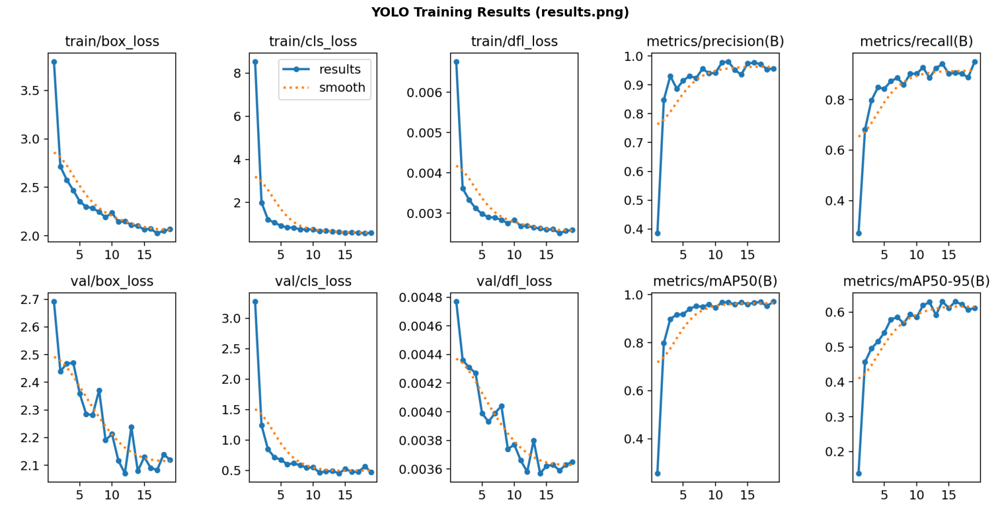

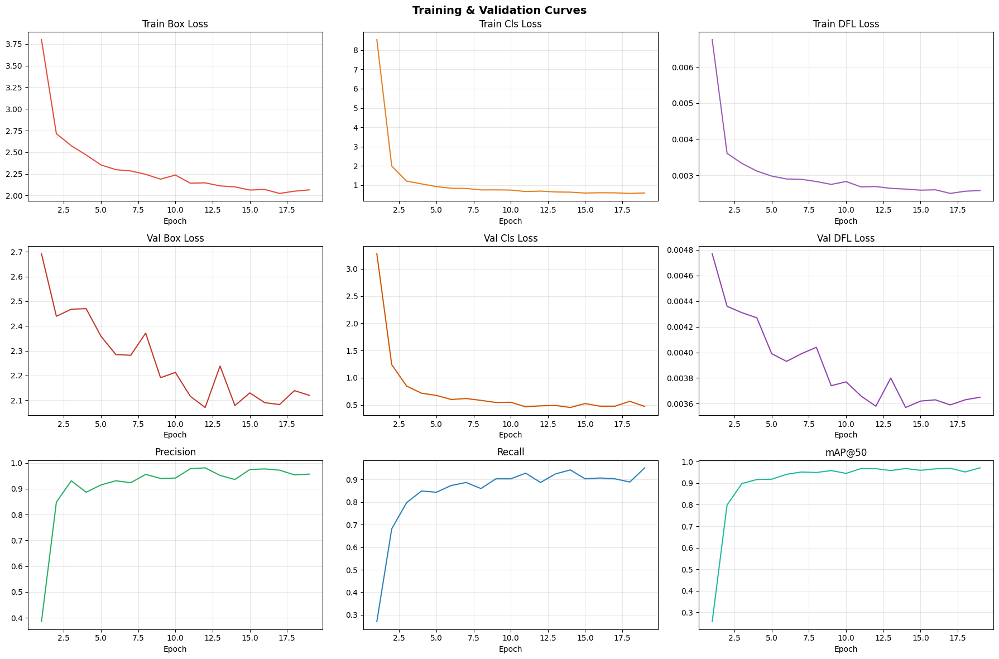

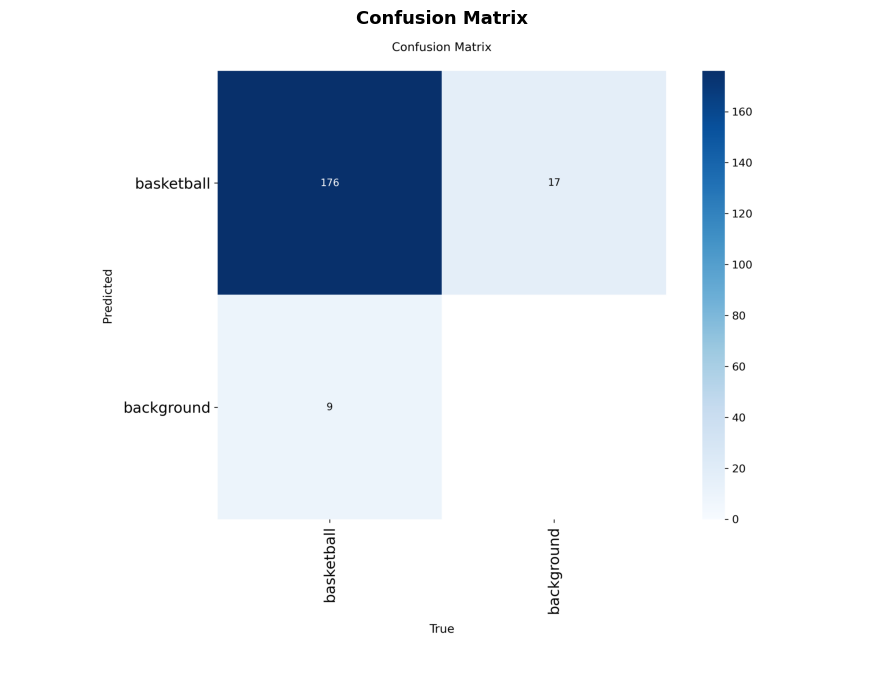

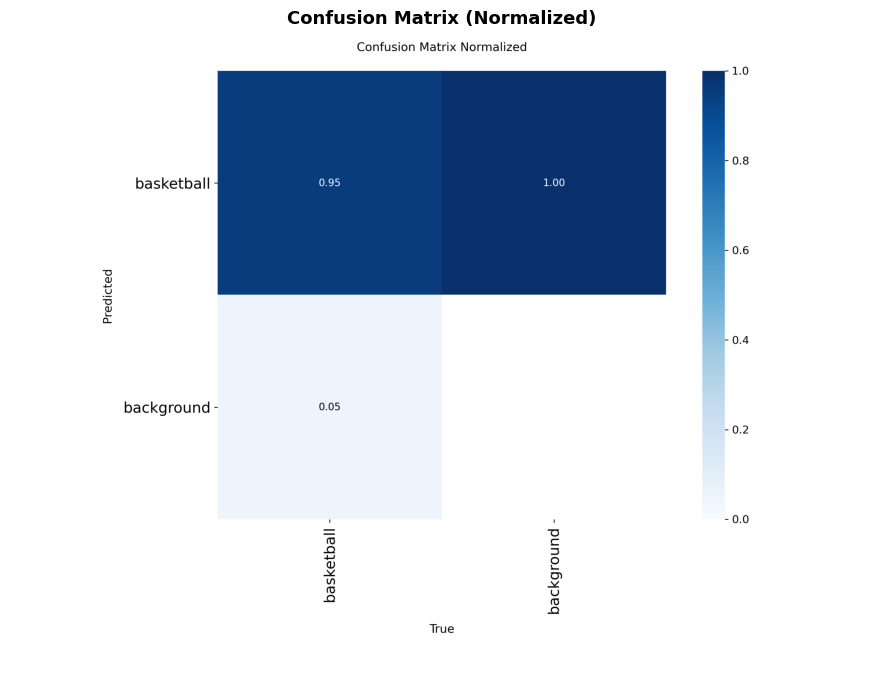

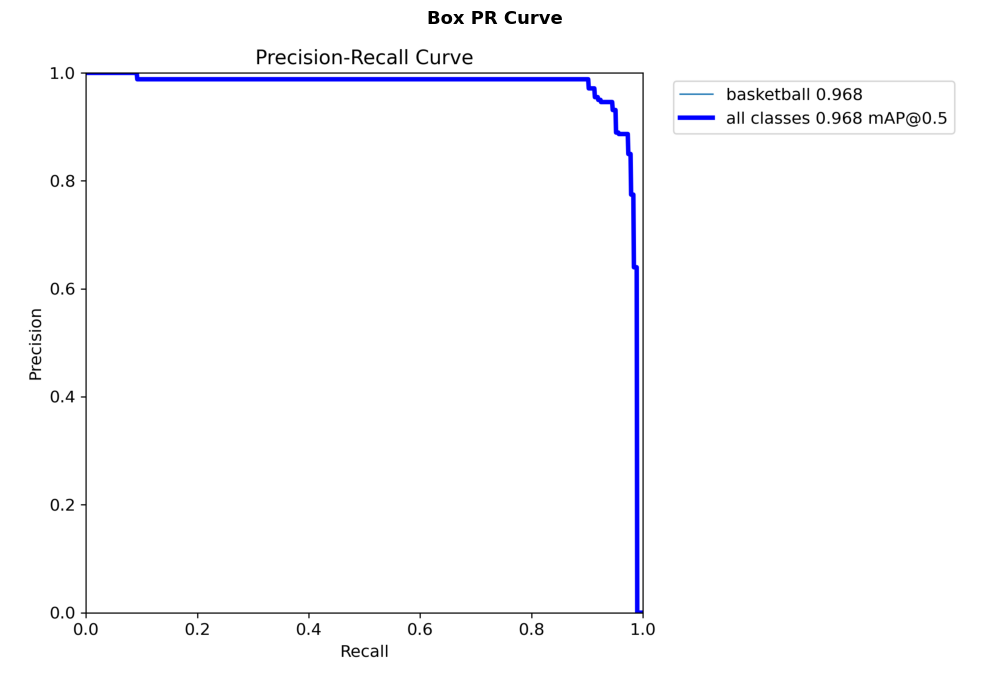

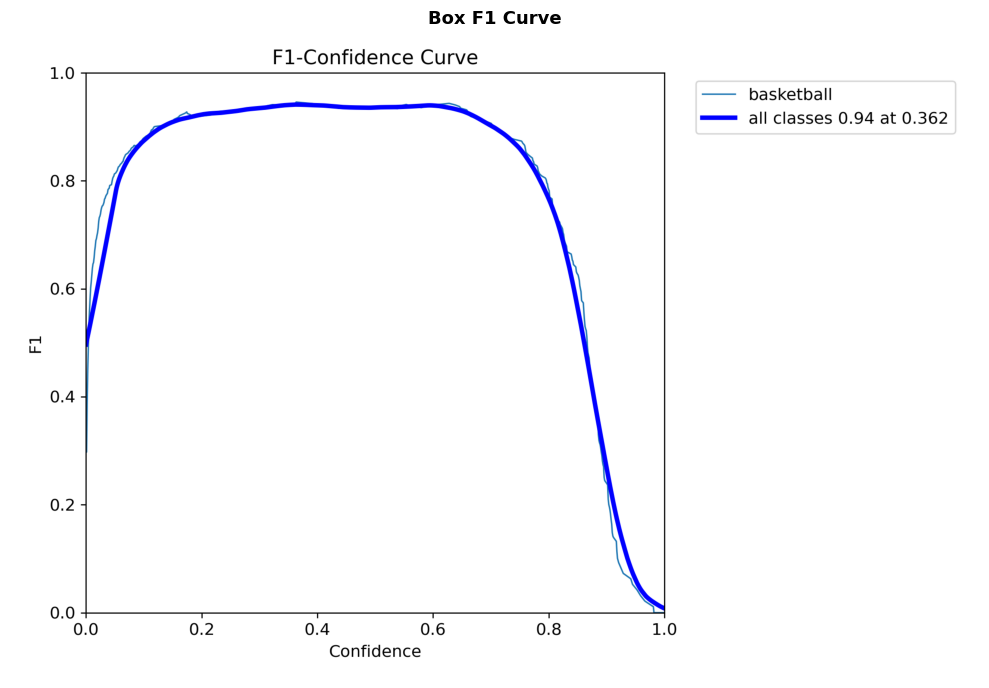

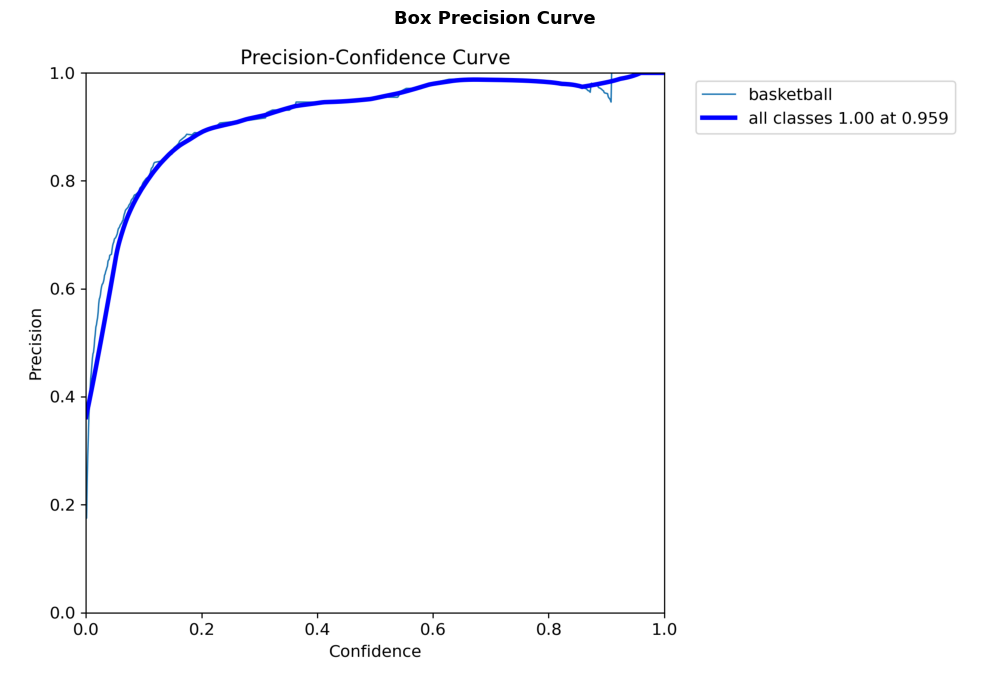

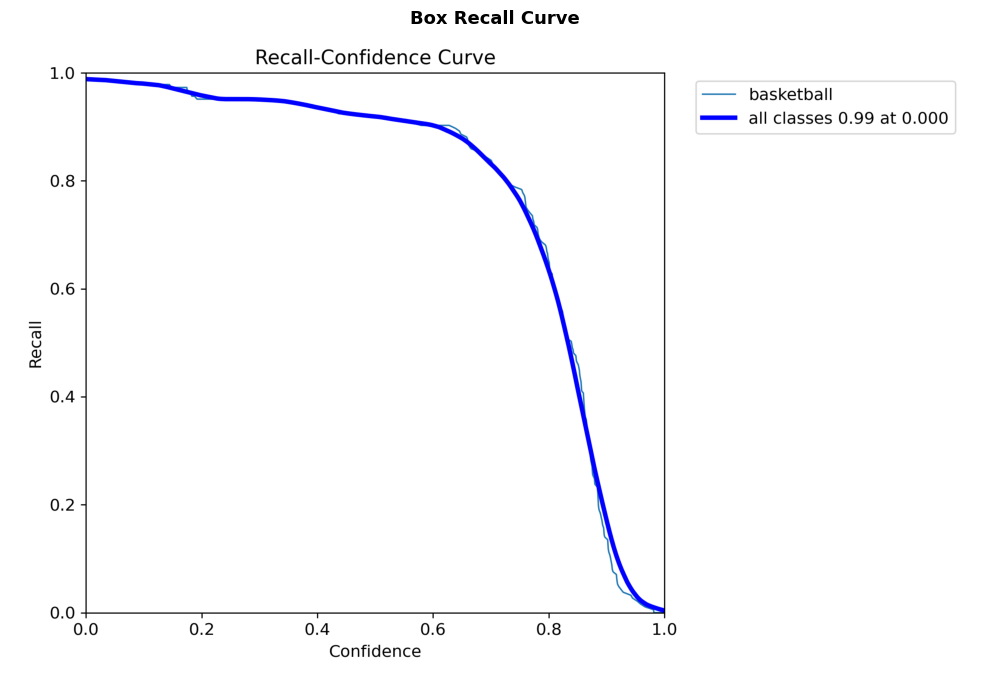

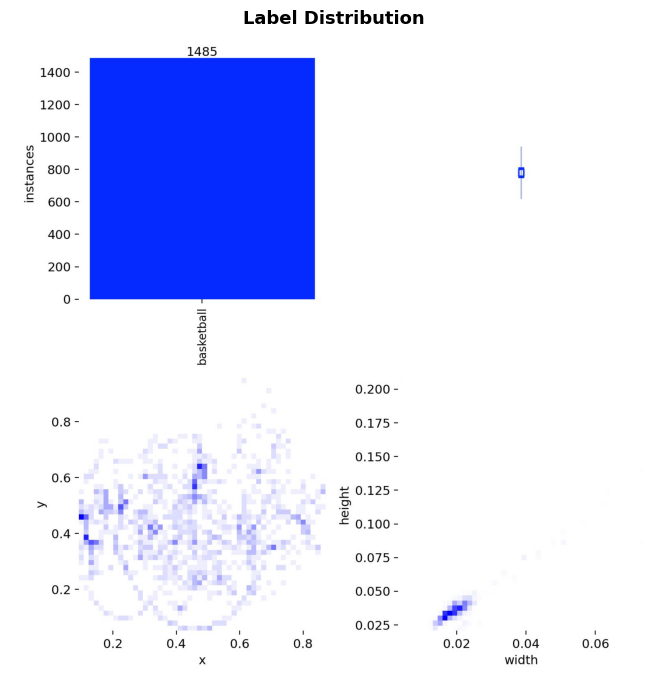

In [ ]:
# -- results.png (YOLO native) ----------------------------------
_rp = plot_files.get('results.png')
if _rp and Path(_rp).exists():
    fig, ax = plt.subplots(figsize=(16, 8))
    ax.imshow(mpimg.imread(str(_rp)))
    ax.set_title('YOLO Training Results (results.png)', fontsize=14, fontweight='bold')
    ax.axis('off'); plt.tight_layout(); plt.show()
else:
    logger.info('results.png not found -- will build from CSV below.')

# -- results.csv curves (also serves Task 5) ----------------
def _load_metrics_csv(csv_path):
    if csv_path is None or not Path(csv_path).exists():
        logger.warning('metrics CSV not found -- skipping.')
        return None
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()
    return df

def _render_curves(df, title='Training Curves', csv_path=None):
    if df is None or df.empty: return
    x = df['epoch'] if 'epoch' in df.columns else df.index
    fig, axes = plt.subplots(3, 3, figsize=(18, 12))
    fig.suptitle(title, fontsize=14, fontweight='bold')
    def sp(ax, col, t, color):
        if col in df.columns:
            ax.plot(x, df[col], color=color, linewidth=1.5)
            ax.set_title(t); ax.set_xlabel('Epoch'); ax.grid(True, alpha=0.3)
        else:
            ax.set_title(f'{t} (N/A)'); ax.axis('off')
    sp(axes[0,0], 'train/box_loss',       'Train Box Loss',  '#e74c3c')
    sp(axes[0,1], 'train/cls_loss',       'Train Cls Loss',  '#e67e22')
    sp(axes[0,2], 'train/dfl_loss',       'Train DFL Loss',  '#9b59b6')
    sp(axes[1,0], 'val/box_loss',         'Val Box Loss',    '#c0392b')
    sp(axes[1,1], 'val/cls_loss',         'Val Cls Loss',    '#d35400')
    sp(axes[1,2], 'val/dfl_loss',         'Val DFL Loss',    '#8e44ad')
    sp(axes[2,0], 'metrics/precision(B)', 'Precision',       '#27ae60')
    sp(axes[2,1], 'metrics/recall(B)',    'Recall',          '#2980b9')
    sp(axes[2,2], 'metrics/mAP50(B)',     'mAP@50',          '#1abc9c')
    plt.tight_layout()
    if csv_path:
        out = Path(csv_path).parent / 'training_curves_custom.png'
        plt.savefig(out, dpi=150); logger.info(f'Curves -> {out}')
    plt.show()

df_metrics = _load_metrics_csv(results_csv_path)
_render_curves(df_metrics, 'Training & Validation Curves', results_csv_path)

# -- 7.1-C Display all YOLO standard image outputs --------------------
_IMG_TITLES = {
    'confusion_matrix.png'           : 'Confusion Matrix',
    'confusion_matrix_normalized.png': 'Confusion Matrix (Normalized)',
    'BoxPR_curve.png'                : 'Box PR Curve',
    'BoxF1_curve.png'                : 'Box F1 Curve',
    'BoxP_curve.png'                 : 'Box Precision Curve',
    'BoxR_curve.png'                 : 'Box Recall Curve',
    'labels.jpg'                     : 'Label Distribution',
    'PR_curve.png'                   : 'PR Curve',
    'F1_curve.png'                   : 'F1 Curve',
}
for _pname, _title in _IMG_TITLES.items():
    _path = plot_files.get(_pname)
    if _path and Path(_path).exists():
        fig, ax = plt.subplots(figsize=(10, 7))
        ax.imshow(mpimg.imread(str(_path)))
        ax.set_title(_title, fontsize=13, fontweight='bold')
        ax.axis('off'); plt.tight_layout(); plt.show()
    else:
        logger.info(f'{_title} ({_pname}): not found.')


### 8.3 · Model evaluation on the test set

In [ ]:
def run_yolo_evaluation(weights_path, data_yaml, split='test'):
    if weights_path is None or not Path(weights_path).exists():
        logger.warning(f'Weights not found at {weights_path} -- skipping {split} eval.')
        return None, None
    logger.info(f'Running YOLO evaluation on split={split} ...')
    val_model   = YOLO(str(weights_path))
    val_results = val_model.val(
        data=str(data_yaml),
        split=split,
        imgsz=HYPERPARAMS['imgsz'],
        device=HYPERPARAMS['device'],
        plots=True,
        save_json=False,
        verbose=True,
    )
    box = val_results.box
    f1_global = 2 * box.mp * box.mr / (box.mp + box.mr + 1e-9)
    agg = {
        'split'    : split,
        'Precision': float(box.mp),
        'Recall'   : float(box.mr),
        'mAP50'    : float(box.map50),
        'mAP50-95' : float(box.map),
        'F1'       : float(f1_global),
    }
    # Per-class metrics
    per_class = {}
    names = val_results.names
    if hasattr(box, 'ap_class_index'):
        for i, cls_idx in enumerate(box.ap_class_index):
            cls_name = names.get(int(cls_idx), f'cls_{cls_idx}')
            p   = float(box.p[i])    if hasattr(box,'p')    else float('nan')
            r   = float(box.r[i])    if hasattr(box,'r')    else float('nan')
            m50 = float(box.ap50[i]) if hasattr(box,'ap50') else float('nan')
            m   = float(box.ap[i])   if hasattr(box,'ap')   else float('nan')
            per_class[cls_name] = {'Precision':p,'Recall':r,'mAP50':m50,'mAP50-95':m,'F1':2*p*r/(p+r+1e-9)}
    logger.info(f'[{split}] P={agg["Precision"]:.4f}  R={agg["Recall"]:.4f}  '
                f'mAP50={agg["mAP50"]:.4f}  mAP50-95={agg["mAP50-95"]:.4f}  F1={agg["F1"]:.4f}')
    return agg, per_class

# Run on TEST split
test_agg, test_per_class = run_yolo_evaluation(best_weights, data_yaml_path, split='test')

# Run on VAL split (for comparison)
val_agg, val_per_class   = run_yolo_evaluation(best_weights, data_yaml_path, split='val')
val_metrics = val_agg or {}


Ultralytics 8.4.72 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 122 layers, 9,465,567 parameters, 0 gradients, 20.5 GFLOPs
val: Fast image access ✅ (ping: 1.0±0.5 ms, read: 21.0±46.4 MB/s, size: 299.3 KB)
val: Scanning /content/drive/.shortcut-targets-by-id/1jblZrI00CBpsLdpQ4DTvH_ptH5p9Md2H/DeepLearningProject/datasets/ball_1858.yolo26/test/labels.cache... 187 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 187/187 46.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 1.6it/s 7.6s
                   all        187        187      0.957      0.925      0.972      0.649
Speed: 1.4ms preprocess, 6.3ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to /content/runs/detect/val
Ultralytics 8.4.72 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 122 layers, 9,465,567 parameters, 0 gradients, 20.5 GFLOPs
val: Fast i

### 8.4 · Saving evaluation results (in 2 separate .json files)

In [ ]:
def _save_metrics_json(agg_dict, per_class_dict, out_path, run_name):
    if agg_dict is None:
        logger.warning(f'No metrics to save for {run_name}.'); return
    payload = {**agg_dict, 'run_name': run_name,
               'timestamp': datetime.datetime.utcnow().isoformat()}
    if per_class_dict:
        payload['per_class'] = per_class_dict
    out_path.parent.mkdir(parents=True, exist_ok=True)
    with open(out_path, 'w') as f:
        json.dump(payload, f, indent=2)
    print(f'Saved -> {out_path}')
    print(json.dumps(payload, indent=2))

_test_json_path = Path("/content/drive/MyDrive/DeepLearningProject/") / PROJECT / NAME/ "completed/test_metrics.json"
_eval_json_path = Path("/content/drive/MyDrive/DeepLearningProject/") / PROJECT / NAME/ "completed/eval_metrics.json"
_save_metrics_json(test_agg, test_per_class, _test_json_path, V2_RUN_NAME + '_test')

metrics_json_path.parent.mkdir(parents=True, exist_ok=True)
if val_agg:
    _save_metrics_json(val_agg, val_per_class, _eval_json_path, V2_RUN_NAME)
resolved_json_v2 = metrics_json_path


Saved -> /content/drive/MyDrive/DeepLearningProject/yolo_ball/train_v4/completed/test_metrics.json
{
  "split": "test",
  "Precision": 0.9571679486184294,
  "Recall": 0.9251336898395722,
  "mAP50": 0.9723568208002245,
  "mAP50-95": 0.648726039232313,
  "F1": 0.9408782285888238,
  "run_name": "train_v4_test",
  "timestamp": "2026-06-20T20:46:25.490851",
  "per_class": {
    "basketball": {
      "Precision": 0.9571679486184294,
      "Recall": 0.9251336898395722,
      "mAP50": 0.9723568208002245,
      "mAP50-95": 0.648726039232313,
      "F1": 0.9408782285888238
    }
  }
}
Saved -> /content/drive/MyDrive/DeepLearningProject/yolo_ball/train_v4/completed/eval_metrics.json
{
  "split": "val",
  "Precision": 0.935526001603242,
  "Recall": 0.9405405405405406,
  "mAP50": 0.9682816540534658,
  "mAP50-95": 0.6299312656697367,
  "F1": 0.9380265688904276,
  "run_name": "train_v4",
  "timestamp": "2026-06-20T20:46:25.502129",
  "per_class": {
    "basketball": {
      "Precision": 0.93552600160

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).


### 8.5 · Comparing results obtained between validation and testing


  TRAIN/VAL (last epoch)  vs  VAL (best.pt)  vs  TEST (best.pt)
                Precision  Recall   mAP50  mAP50-95      F1
Val@last-epoch     0.9565  0.9513  0.9714    0.6122     NaN
Val@best-pt        0.9355  0.9405  0.9683    0.6299  0.9380
Test@best-pt       0.9572  0.9251  0.9724    0.6487  0.9409


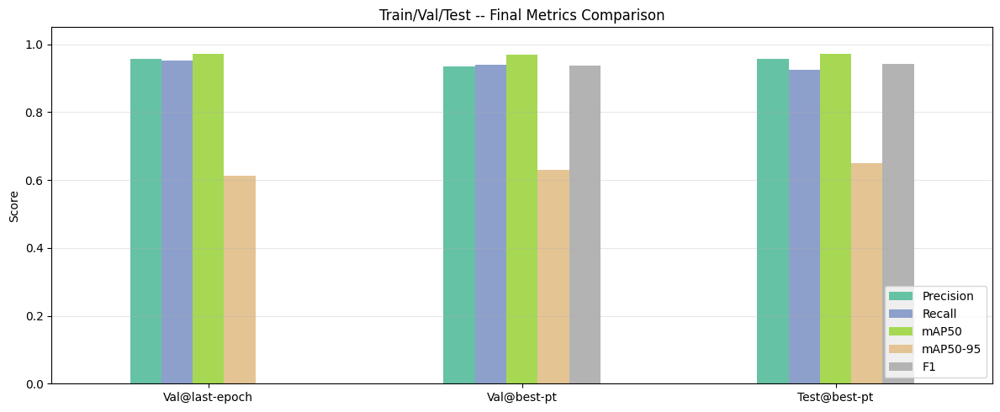

In [ ]:
def compare_train_test(df_train_csv, val_agg_dict, test_agg_dict):
    print('\n' + '='*70)
    print('  TRAIN/VAL (last epoch)  vs  VAL (best.pt)  vs  TEST (best.pt)')
    print('='*70)
    rows = {}
    # Last epoch from training CSV
    if df_train_csv is not None and not df_train_csv.empty:
        last = df_train_csv.iloc[-1]
        rows['Val@last-epoch'] = {
            'Precision' : last.get('metrics/precision(B)', float('nan')),
            'Recall'    : last.get('metrics/recall(B)',    float('nan')),
            'mAP50'     : last.get('metrics/mAP50(B)',     float('nan')),
            'mAP50-95'  : last.get('metrics/mAP50-95(B)',  float('nan')),
            'F1'        : float('nan'),
        }
    if val_agg_dict:
        rows['Val@best-pt'] = {k: val_agg_dict.get(k, float('nan'))
                                for k in ['Precision','Recall','mAP50','mAP50-95','F1']}
    if test_agg_dict:
        rows['Test@best-pt'] = {k: test_agg_dict.get(k, float('nan'))
                                 for k in ['Precision','Recall','mAP50','mAP50-95','F1']}
    df_cmp = pd.DataFrame(rows).T
    print(df_cmp.round(4).to_string())
    ax = df_cmp.astype(float).plot(
        kind='bar', figsize=(12, 5), rot=0,
        title='Train/Val/Test -- Final Metrics Comparison', colormap='Set2'
    )
    ax.set_ylabel('Score'); ax.set_ylim(0, 1.05)
    ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)
    plt.tight_layout(); plt.show()
    return df_cmp

df_comparison = compare_train_test(df_metrics, val_agg, test_agg)

## 9 · Analysis between different versions

### 9.1 · Loading .json files with the metric values ​​obtained from all trained models

In [ ]:
sns.set_theme(style='whitegrid', font_scale=1.1)

# ── Config ────────────────────────────────────────────────────────────────────
BASE_DIR = Path("/content/drive/MyDrive/DeepLearningProject/") / PROJECT
OUTPUT_DIR = BASE_DIR / "results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Discover all train_v* folders ─────────────────────────────────────────────
pattern = str(BASE_DIR / "train_v*" / "completed" / "test_metrics.json")
found_paths = sorted(glob.glob(pattern))

if not found_paths:
    raise FileNotFoundError(
        f"No test_metrics.json files found matching:\n  {pattern}\n"
        "Check that PROJECT is set correctly and the drive is mounted."
    )

print(f"✅ Found {len(found_paths)} model(s):")
for p in found_paths:
    print(f"   • {Path(p).parts[-3]}")

# ── Parse each JSON into flat dicts ───────────────────────────────────────────
def parse_metrics_json(path: Path) -> dict:
    with open(path) as f:
        data = json.load(f)

    name = path.parts[-3]  # e.g. "train_v3"

    model_row = {"model": name}
    for key in (
        "mAP50-95", "mAP50", "Precision", "Recall", "F1",
        "FPS", "latency_ms", "params_M", "GFLOPs",
        "file_size_MB", "Size"
    ):
        model_row[key] = data.get(key, np.nan)

    return model_row

# ── Build dataframe ───────────────────────────────────────────────────────────
all_model_rows = []

for p in found_paths:
    all_model_rows.append(parse_metrics_json(Path(p)))

df_all = pd.DataFrame(all_model_rows)

# ── Save ──────────────────────────────────────────────────────────────────────
df_all.to_csv(OUTPUT_DIR / "all_metrics.csv", index=False)

print("\nMODEL-LEVEL METRICS")

NUMERIC_METRICS = [
    c for c in ['mAP50-95', 'mAP50', 'Precision', 'Recall', 'F1']
    if c in df_all.columns
]

print(
    tabulate(
        df_all[['model'] + NUMERIC_METRICS],
        headers='keys',
        tablefmt='rounded_outline',
        floatfmt='.4f',
        showindex=False
    )
)

print(f"\nSaved → {OUTPUT_DIR / 'all_metrics.csv'}")

✅ Found 5 model(s):
   • train_v1
   • train_v2
   • train_v3
   • train_v4
   • train_v5

MODEL-LEVEL METRICS
╭──────────┬────────────┬─────────┬─────────────┬──────────┬────────╮
│ model    │   mAP50-95 │   mAP50 │   Precision │   Recall │     F1 │
├──────────┼────────────┼─────────┼─────────────┼──────────┼────────┤
│ train_v1 │     0.5180 │  0.9109 │      0.8910 │   0.8305 │ 0.8597 │
│ train_v2 │     0.6563 │  0.9839 │      0.9945 │   0.9657 │ 0.9799 │
│ train_v3 │     0.7149 │  0.9927 │      0.9890 │   0.9609 │ 0.9747 │
│ train_v4 │     0.6487 │  0.9724 │      0.9572 │   0.9251 │ 0.9409 │
│ train_v5 │     0.7124 │  0.9926 │      0.9841 │   0.9733 │ 0.9787 │
╰──────────┴────────────┴─────────┴─────────────┴──────────┴────────╯

Saved → /content/drive/MyDrive/DeepLearningProject/yolo_ball/results/all_metrics.csv


### 9.2 · Final Benchmark Report

In [ ]:
print("=" * 70)
print("  FINAL BENCHMARK REPORT")
print("=" * 70)

essential = ["mAP50-95", "mAP50", "Precision", "Recall", "F1"]

e_cols = [m for m in essential if m in df_all.columns]

print("\n── METRICS ─────────────────────────────────────────")
print(
    tabulate(
        df_all[['model'] + e_cols],
        headers='keys',
        tablefmt='rounded_outline',
        floatfmt='.4f',
        showindex=False
    )
)

# ── Best model per metric ─────────────────────────────────────────────────────
print("\n── BEST MODEL PER METRIC ─────────────────────────────────────")

best_rows = []

for m in e_cols:
    col = df_all[m].dropna()

    if col.empty:
        continue

    best_idx = col.idxmax()

    best_rows.append([
        m,
        "↑ higher is better",
        df_all.loc[best_idx, 'model'],
        round(df_all.loc[best_idx, m], 4)
    ])

print(
    tabulate(
        best_rows,
        headers=['Metric', 'Direction', 'Best Model', 'Value'],
        tablefmt='rounded_outline'
    )
)

print(f"\nAll outputs saved in: {OUTPUT_DIR.resolve()}")
print("   Files:")

for f in sorted(OUTPUT_DIR.glob("*.csv")) + sorted(OUTPUT_DIR.glob("*.png")):
    print(f"   • {f.name}")

  FINAL BENCHMARK REPORT

── METRICS ─────────────────────────────────────────
╭──────────┬────────────┬─────────┬─────────────┬──────────┬────────╮
│ model    │   mAP50-95 │   mAP50 │   Precision │   Recall │     F1 │
├──────────┼────────────┼─────────┼─────────────┼──────────┼────────┤
│ train_v1 │     0.5180 │  0.9109 │      0.8910 │   0.8305 │ 0.8597 │
│ train_v2 │     0.6563 │  0.9839 │      0.9945 │   0.9657 │ 0.9799 │
│ train_v3 │     0.7149 │  0.9927 │      0.9890 │   0.9609 │ 0.9747 │
│ train_v4 │     0.6487 │  0.9724 │      0.9572 │   0.9251 │ 0.9409 │
│ train_v5 │     0.7124 │  0.9926 │      0.9841 │   0.9733 │ 0.9787 │
╰──────────┴────────────┴─────────┴─────────────┴──────────┴────────╯

── BEST MODEL PER METRIC ─────────────────────────────────────
╭───────────┬────────────────────┬──────────────┬─────────╮
│ Metric    │ Direction          │ Best Model   │   Value │
├───────────┼────────────────────┼──────────────┼─────────┤
│ mAP50-95  │ ↑ higher is better │ train_v3    

### 9.3 · Results visualization

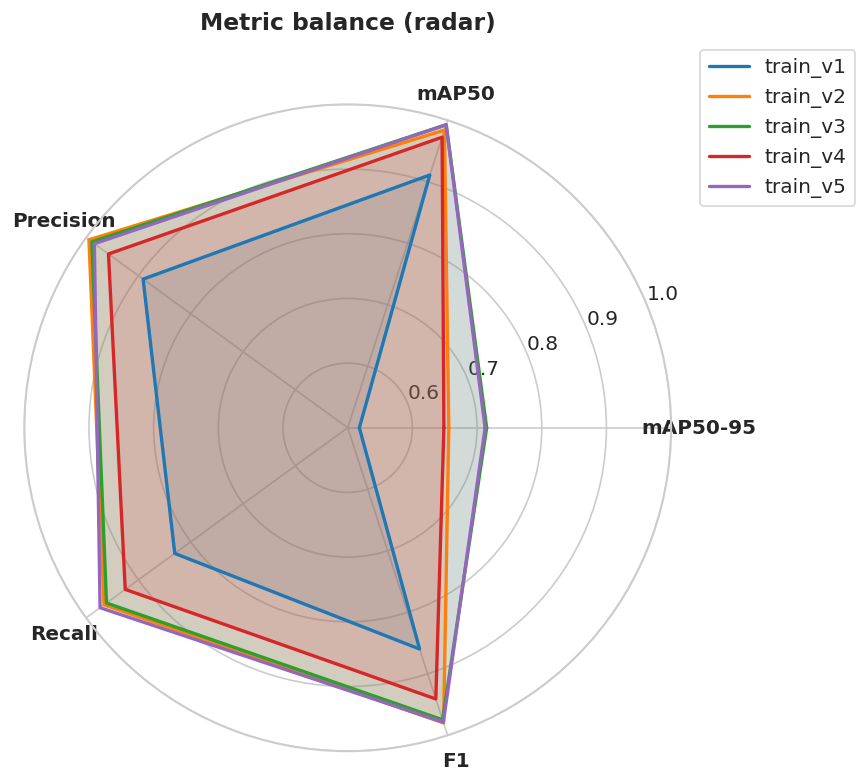

In [ ]:
unique_models = df_all['model'].tolist()
palette = sns.color_palette("tab10", len(unique_models))
MODEL_COLORS = dict(zip(unique_models, palette))

fig = plt.figure(figsize=(16, 7))

# ── Radar (overall) ───────────────────────────────────────────────────────────
ax1 = fig.add_subplot(121, polar=True)

metrics_radar = ["mAP50-95", "mAP50", "Precision", "Recall", "F1"]
N      = len(metrics_radar)

angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]  # close loop

for _, row in df_all.iterrows():
    if all(m in row for m in metrics_radar) and not np.isnan(row['mAP50']):

        values = row[metrics_radar].values.flatten().tolist()
        values += values[:1]

        color = MODEL_COLORS.get(row['model'], "#333")

        ax1.plot(angles, values, linewidth=2, label=row['model'], color=color)
        ax1.fill(angles, values, color=color, alpha=0.15)

# axis styling
ax1.set_xticks(angles[:-1])
ax1.set_xticklabels(metrics_radar, fontsize=12, fontweight='bold')

# CHANGED RANGE
ax1.set_ylim(0.50, 1.0)

ax1.set_title('Metric balance (radar)', size=14, y=1.1, fontweight='bold')

ax1.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))


## 10 · HYPERPARAMETERS TUNING



### 10.1 · Importing libraries for hyperparameter tuning

In [ ]:
# These packages are not included in the default Ultralytics installation.
# ray[tune] provides distributed hyperparameter tuning utilities.
# optuna is used as the Bayesian optimization backend.

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "ray[tune]",   # Ray core + Tune scheduler/search API
    "optuna",      # Bayesian search backend used by Ray Tune
    "--quiet",
])
print("✅  ray[tune] and optuna installed.")


import ray
from ray import tune
from ray.tune.schedulers import ASHAScheduler
from ray.tune.search.optuna import OptunaSearch
from ray.tune import JupyterNotebookReporter

✅  ray[tune] and optuna installed.


### 10.2 · Paths definition

In [ ]:
# All Ray Tune trial checkpoints and results are written directly to Drive.

if not os.path.ismount('/content/drive'):
    drive.mount('/content/drive', force_remount=False)

# Root directory on Drive where the entire tuning experiment will be stored.
# Ray Tune creates one sub-folder per trial inside this directory.
DRIVE_STORAGE_DIR = Path("/content/drive/MyDrive/DeepLearningProject/") / PROJECT /"Tuning"
DRIVE_STORAGE_DIR.mkdir(parents=True, exist_ok=True)

print(f"✅  Drive mounted.  Storage → {DRIVE_STORAGE_DIR}")

✅  Drive mounted.  Storage → /content/drive/MyDrive/DeepLearningProject/yolo_ball/Tuning


### 10.3 · Loading on local device

In [ ]:
logger = logging.getLogger(__name__)

def ensure_local_dataset_auto_zip(
    drive_base_path: str,
    dataset_name: str,
    local_base_path: str = "/content/dataset",
    force_copy: bool = False
) -> str:
    """
    Checks for a zipped dataset on Drive, creates it if missing,
    and extracts it to the local Colab SSD for maximum speed.
    """
    drive_folder = Path(drive_base_path) / dataset_name
    drive_zip = Path(drive_base_path) / f"{dataset_name}.zip"

    local_path = Path(local_base_path)
    local_zip_temp = Path(f"/content/{dataset_name}_temp.zip")

    # ==========================================
    # 1. Check if already extracted locally
    # ==========================================
    already_exists = local_path.exists() and (local_path / "data.yaml").exists()

    if already_exists and not force_copy:
        print(f"Local dataset already exists at {local_path} — skipping copy")
        return str(local_path)

    # Clean up existing local folder if forcing a re-copy
    if local_path.exists() and force_copy:
        print(f"Removing existing local dataset at {local_path}")
        shutil.rmtree(local_path)

    local_path.mkdir(parents=True, exist_ok=True)

    # ==========================================
    # 2. Ensure the ZIP exists on Google Drive
    # ==========================================
    if not drive_zip.exists():
        if not drive_folder.exists():
            raise FileNotFoundError(f"❌ Cannot find source dataset folder: {drive_folder}")

        print(f"ZIP file not found on Drive. Creating it now...")
        print(f"   (This is a ONE-TIME process. It may take a few minutes but will make all future runs instant)")

        # We use the Linux zip command inside subprocess because it handles FUSE network
        # drives much faster than Python's shutil.make_archive.
        # We cd into the folder first so the zip doesn't contain absolute folder structures.
        parent_folder = drive_folder.parent
        zip_cmd = f"cd '{parent_folder}' && zip -r -q '{drive_zip}' '{dataset_name}'"
        subprocess.run(zip_cmd, shell=True, check=True)
        print(f"✅ ZIP file created successfully on Drive at {drive_zip}")
    else:
        print(f"✅ Found existing ZIP file on Drive: {drive_zip}")

    # ==========================================
    # 3. Transfer and Extract
    # ==========================================
    print("Copying ZIP from Drive → local SSD...")
    shutil.copy2(drive_zip, local_zip_temp)

    print("Unzipping dataset locally...")
    subprocess.run(["unzip", "-q", str(local_zip_temp), "-d", str(local_path)], check=True)

    # Cleanup the temporary zip file to save Colab SSD space
    if local_zip_temp.exists():
        os.remove(local_zip_temp)

    print("✅ Dataset successfully copied and extracted to local SSD")
    return str(local_path)



drive_base_path= Path("/content/drive/MyDrive/DeepLearningProject/datasets")
DATASET_PATH = ensure_local_dataset_auto_zip(
    drive_base_path=drive_base_path,
    dataset_name=dataset_name,
    local_base_path="/content/dataset",
    force_copy=False
)


data_yaml_path = Path("/content/dataset")/dataset_name/"data.yaml"

✅ Found existing ZIP file on Drive: /content/drive/MyDrive/DeepLearningProject/datasets/ball_1858.yolo26.zip
Copying ZIP from Drive → local SSD...
Unzipping dataset locally...
✅ Dataset successfully copied and extracted to local SSD


### 10.4 · Configuration

In [ ]:
# Path to the dataset YAML (must already exist from the download cell above).
DATASET_YAML_PATH = data_yaml_path

# Model weights — reloaded fresh inside every trial to avoid shared state.
MODEL_WEIGHTS = "yolo26s.pt"

# Total wall-clock budget for the entire tuning session (seconds).
# 100 hours.
TOTAL_TIME_BUDGET_S = 100 * 60 * 60  # 100 ore

# Maximum concurrent trials.
# run sequentially without VRAM contention.
MAX_CONCURRENT_TRIALS = 1

### 10.5 · Definition of the parameter space and the search function

In [ ]:
# Only the parameters specified are searched; everything else is locked
# to the values in HYPERPARAMS (imported from the training config cell).

SEARCH_SPACE = {

    # --- Bounding box precision ---
    "box":        tune.uniform(8.0, 15.0),
    "dfl":        tune.uniform(1.5, 3.0),

    # --- Recall & Class Imbalance ---
    # Penalizes False Negatives more heavily.
    "cls_pw": tune.uniform(0.0, 1.0),

    # Pastes minority objects.
    "copy_paste": tune.uniform(0.1, 0.3),

    # --- Learning Rate ---
    # L2 regularization applied to the weights (weight decay) helps reduce
    # overfitting improving generalization.
    "lr0":        tune.loguniform(5e-4, 5e-3),
    "weight_decay": tune.loguniform(1e-4, 2e-3),

    # --- Small Object Preservation ---
    # Reduced from (0.3, 0.5). In YOLO, scale=0.5 means +/- 50% zooming.
    # Lowering this prevents ball from shrinking out of existence.
    "scale":      tune.uniform(0.05, 0.25),

    # Mixup: Bumped the minimum slightly above 0 to ensure the network is forced
    # to learn occluded features
    #"mixup":      tune.uniform(0.05, 0.15),

    # --- Context & Sizing ---
    # Mosaic stitches 4 images together. High mosaic gives great global context
    # but shrinks objects. Tuning this helps find the sweet spot where the ball
    # doesn't become too small to detect.
    #"mosaic":     tune.uniform(0.0, 0.25),


    # --- Color & Lighting Robustness ---
    # Basketball courts have glare, shadows, and highly saturated colors.
    # Tuning saturation (hsv_s) and brightness/value (hsv_v) ensures the model
    # doesn't over-rely on the exact same color to find the ball.
    "hsv_s":      tune.uniform(0.15, 0.45),
    "hsv_v":      tune.uniform(0.10, 0.35),
}

### 10.6 · Define the train function

In [ ]:
# Ray Tune calls this function once per trial, passing a `config` dict
# sampled from SEARCH_SPACE.  We train for a short proxy task (20 epochs,
# 30 % of data) and report the mAP50-95(B) metric back to the scheduler.

def train_yolo_trial(config: dict) -> None:
    """
    Single Ray Tune trial.

    Parameters
    ----------
    config : dict
        Sampled hyperparameter values from SEARCH_SPACE.
    """
    # Fresh model per trial — never share a model object across trials.
    model = YOLO(MODEL_WEIGHTS)

    # Merge locked base hyperparameters with the sampled search values.
    # Sampled values deliberately override any matching keys in HYPERPARAMS.
    trial_kwargs = {
        # ── Locked proxy-task constraints (do NOT tune these) ──
        "data":     DATASET_YAML_PATH,
        "epochs":   20,          # Short proxy — enough signal for mAP50-95
        "fraction": 0.3,         # Use only 30 % of dataset → fast iterations
        "imgsz":    640,         # Fixed to avoid OOM on T4
        "batch":    16,          # Fixed to avoid OOM on T4
        "device":   0,           # GPU 0
        "verbose":  False,       # Suppress per-epoch stdout inside Ray workers
        "plots":    False,       # Skip plot generation to save I/O time
        "val":      True,        # Validation is required to get the metric

        # ── Inherited base hyperparameters ─────────────────────
        # Pull optimizer / regularisation / augmentation defaults from the
        # notebook's HYPERPARAMS dict (defined in the config cell above).
        # The four searched keys below will overwrite any matching entries.
        **{k: v for k, v in HYPERPARAMS.items()
           if k not in ("epochs", "batch", "imgsz", "device",
                        "project", "name", "exist_ok", "verbose",
                        "save_period", "fraction")},

        # ── Sampled search-space values ─────────────────────────
        "box":   config["box"],
        "dfl":   config["dfl"],
        "mixup": config["mixup"],
        "scale": config["scale"],
        "cls_pw": config["cls_pw"],
        "copy_paste": config["copy_paste"],
        "lr0": config["lr0"],
        "weight_decay": config["weight_decay"],
        "mosaic": config["mosaic"],
        "hsv_s": config["hsv_s"],
        "hsv_v": config["hsv_v"],
        "erasing": config["erasing"],
    }

    # Train the model.  results() returns a Results object with all metrics.
    results = model.train(**trial_kwargs)

    # ── Extract the target metric ──────────────────────────────────────────
    # Ultralytics stores metrics in results.results_dict.
    # Key: "metrics/mAP50-95(B)" — bounding-box mAP averaged over IoU 0.5:0.95.
    metrics_dict = results.results_dict if hasattr(results, "results_dict") else {}
    map_score = metrics_dict.get("metrics/mAP50-95(B)", 0.0)

    # Report the metric to Ray Tune.  The scheduler uses this to decide
    # whether to prune (stop early) or continue the trial.
    tune.report({"metrics/mAP50-95(B)": map_score})

### 10.7 · Configure the scheduler and search algorithm

In [ ]:
# ASHAScheduler — Asynchronous Successive Halving Algorithm.
# Aggressively terminates underperforming trials early, freeing time for
# more promising regions of the search space.
asha_scheduler = ASHAScheduler(
    # Maximum number of proxy epochs a single trial is ever allowed to run.
    # Must match or exceed the `epochs` value passed to model.train().
    max_t=20,

    # Grace period — every trial runs at least this many epochs before
    # ASHA is allowed to prune it.  Too low → kills trials prematurely.
    grace_period=5,

    # Halving factor: at each bracket level only 1/reduction_factor trials
    # survive.
    # 3 (33% of trial survives) is the standard because of exploration,
    # exploitation and computational cost. It's a good compromise for YOLO
    # because bad configuration are spotted early.
    reduction_factor=3,
)

# OptunaSearch — Bayesian/TPE search backed by Optuna.
# Unlike random search, Optuna models the objective surface and proposes
# configs that are likely to improve on previous results.
optuna_search = OptunaSearch()

### 10.8 · Start searching

WARNING: Use this cell only to start a new search; otherwise, use cell 10.9 (to resume a previously interrupted search).

In [ ]:
# Ignore if Ray is already initialised (e.g. notebook was partially run).

# 1. Kill the stuck/zombie Ray cluster
ray.shutdown()
if not ray.is_initialized():
    # log_to_driver=False stops YOLO's progress bars from flooding the cell
    ray.init(ignore_reinit_error=True, log_to_driver=False)
    print("✅  Ray initialised.")


# ── Launch the tuning job ─────────────────────────────────────────

print(f"\nStarting 4-hour tuning session.  Results → {DRIVE_STORAGE_DIR}\n")
start_time = time.time()

tuner = tune.Tuner(
    # Trainable function — called once per trial.
    tune.with_resources(
        train_yolo_trial,
        resources={"gpu": 1, "cpu": 2},
    ),

    param_space=SEARCH_SPACE,

    tune_config=tune.TuneConfig(
        search_alg=optuna_search,
        scheduler=asha_scheduler,
        metric="metrics/mAP50-95(B)",
        mode="max",
        time_budget_s=TOTAL_TIME_BUDGET_S,
        max_concurrent_trials=MAX_CONCURRENT_TRIALS,
        num_samples=200,
    ),

    run_config=tune.RunConfig(
        name="yolo26s_hparam_search",
        storage_path=str(DRIVE_STORAGE_DIR),

        # ── CRITICAL: Use the notebook reporter to prevent table spam ──────
        progress_reporter=JupyterNotebookReporter(
            overwrite=True,
            max_report_frequency=10 # Updates the dashboard every 10 seconds
        ),
        verbose=2, # Required for JupyterNotebookReporter to show the table
    ),
)

# .fit() blocks until the time budget expires or all trials finish.
results = tuner.fit()

elapsed = (time.time() - start_time) / 60
print(f"\n✅  Tuning complete.  Wall time: {elapsed:.1f} min")

[I 2026-06-09 09:09:18,650] A new study created in memory with name: optuna
2026-06-09 09:09:19,006	WARNING tune.py:894 -- AIR_VERBOSITY is set, ignoring passed-in ProgressReporter for now.


Output streaming troncato alle ultime 5000 righe.
| metrics/mAP50(B)                           0.71364 |
| metrics/mAP50-95(B)                        0.39758 |
| metrics/precision(B)                       0.76565 |
| metrics/recall(B)                          0.68649 |
| val/box_loss                               2.54059 |
| val/cls_loss                               1.31982 |
| val/dfl_loss                               0.00425 |
+----------------------------------------------------+

Trial train_yolo_trial_da2e51a1 finished iteration 16 at 2026-06-09 09:42:44. Total running time: 33min 25s
+----------------------------------------------------+
| Trial train_yolo_trial_da2e51a1 result             |
+----------------------------------------------------+
| checkpoint_dir_name                                |
| time_this_iter_s                           17.4739 |
| time_total_s                               280.443 |
| training_iteration                              16 |
| epoch         

2026-06-09 10:32:06,415	WARNING tune.py:219 -- Stop signal received (e.g. via SIGINT/Ctrl+C), ending Ray Tune run. This will try to checkpoint the experiment state one last time. Press CTRL+C (or send SIGINT/SIGKILL/SIGTERM) to skip. 
2026-06-09 10:32:08,365	INFO tune.py:1001 -- Wrote the latest version of all result files and experiment state to '/content/drive/MyDrive/DeepLearningProject/yolo_ball/Tuning/yolo26s_hparam_search' in 1.9484s.



Trial status: 22 TERMINATED | 1 RUNNING
Current time: 2026-06-09 10:32:08. Total running time: 1hr 22min 49s
Logical resource usage: 2.0/2 CPUs, 1.0/1 GPUs (0.0/1.0 accelerator_type:T4)
Current best trial: 083c3e2c with metrics/mAP50-95(B)=0.4116419856638168 and params={'box': 12.378313211715614, 'dfl': 2.4336290632730866, 'cls_pw': 0.35045209837392605, 'copy_paste': 0.2295431996288076, 'lr0': 0.0031815224810365812, 'weight_decay': 0.0018229140609802151, 'scale': 0.1043183311833761, 'mixup': 0.07451513381901773, 'erasing': 0.571877406607912, 'mosaic': 0.19914373080338788, 'hsv_s': 0.44831905653320414, 'hsv_v': 0.34190446810030056}
+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
| Trial name                  status         

KeyboardInterrupt: 

### 10.9 · Restore crashed session

WARNING:

Run this section only to resume an interrupted search (if section 10.8 has not been started).
- Use the fit() command to resume training.
- Use the get_results() command to easily load search results for section 10.10.


In [ ]:
# Force Ray to use Jupyter-friendly formatting on restore
os.environ["RAY_TUNE_REPORTER"] = "jupyter"

# 1. Mount Drive
drive.mount("/content/drive", force_remount=False)

# 2. Re-Initialize Ray (Identical to Step 7 to prevent spam)
ray.shutdown()
if not ray.is_initialized():
    ray.init(ignore_reinit_error=True, log_to_driver=False)
    print("✅  Ray initialised.")

# Define paths (Ensure 'PROJECT' variable is defined in a previous cell)
DRIVE_STORAGE_DIR = Path("/content/drive/MyDrive/DeepLearningProject") / PROJECT / "Tuning"
EXPERIMENT_NAME   = "yolo26s_hparam_search"
experiment_path   = str(DRIVE_STORAGE_DIR / EXPERIMENT_NAME)

print(f"\nRestoring crashed tuning session from → {experiment_path}\n")
start_time = time.time()

# 3. Restore the Tuner WITH GPU resources
restored_tuner = tune.Tuner.restore(
    path=experiment_path,

    # ── Explicitly demand GPU allocation again ──
    trainable=tune.with_resources(
        train_yolo_trial,
        resources={"gpu": 1, "cpu": 2}
    ),

    # Tells Ray to pick up interrupted trials and retry failed ones
    resume_unfinished=True,
    resume_errored=True,
)

# 4. Resume the training
results = restored_tuner.fit()

elapsed = (time.time() - start_time) / 60
print(f"\n✅  Restored tuning complete.  Wall time (this session): {elapsed:.1f} min")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


2026-06-12 11:40:20,552	INFO worker.py:2012 -- Started a local Ray instance.
Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0


✅  Ray initialised.

🚀  Restoring crashed tuning session from → /content/drive/MyDrive/DeepLearningProject/yolo_ball/Tuning/yolo26s_hparam_search



2026-06-12 11:40:58,310	WARNING tune.py:894 -- AIR_VERBOSITY is set, ignoring passed-in ProgressReporter for now.
2026-06-12 11:40:58,375	INFO tune_controller.py:441 -- Restoring the run from the latest experiment state file: experiment_state-2026-06-11_12-38-22.json


Output streaming troncato alle ultime 5000 righe.
| time_total_s                               107.631 |
| training_iteration                               4 |
| epoch                                            4 |
| metrics/mAP50(B)                           0.60671 |
| metrics/mAP50-95(B)                        0.32196 |
| metrics/precision(B)                       0.70297 |
| metrics/recall(B)                          0.56757 |
| val/box_loss                               2.54549 |
| val/cls_loss                               1.99109 |
| val/dfl_loss                               0.00515 |
+----------------------------------------------------+

Trial status: 111 TERMINATED | 1 RUNNING
Current time: 2026-06-12 12:57:44. Total running time: 1hr 16min 38s
Logical resource usage: 2.0/2 CPUs, 1.0/1 GPUs (0.0/1.0 accelerator_type:T4)
Current best trial: 3f52a5f9 with metrics/mAP50-95(B)=0.42503295914031397 and params={'box': 11.473449710688572, 'dfl': 2.987972537291894, 'cls_pw': 0.355486

### 10.10 · Results

#### 10.10.1 · Retrieve results

In [ ]:
DRIVE_STORAGE_DIR = Path("/content/drive/MyDrive/DeepLearningProject") / PROJECT / "Tuning"

# List of all the directories to combine, in chronological order
experiment_names = [
    "yolo26s_hparam_search"
]

TARGET_METRIC = "metrics/mAP50-95(B)"
all_results_dfs = []

print("Extracting and merging historical search data...\n")

for exp_name in experiment_names:
    exp_path = str(DRIVE_STORAGE_DIR / exp_name)
    try:
        # We only restore to read the results, but we need to define trainable/resources here
        tuner = tune.Tuner.restore(
            path=exp_path,
            trainable=tune.with_resources(
                train_yolo_trial,
                resources={"gpu": 1, "cpu": 2}
            )
        )
        results = tuner.get_results()

        print("Total trials:", len(results))

        for i, result in enumerate(results):

            metric = result.metrics.get("metrics/mAP50-95(B)")

            print(
                i,
                result.error,
                metric
            )

        # Extract to DataFrame
        df = results.get_dataframe(filter_metric=TARGET_METRIC, filter_mode="max")
        all_results_dfs.append(df)
        print(f"✅ Loaded {len(df)} trials from: {exp_name}")

    except Exception as e:
        print(f"❌ Could not load {exp_name}. Error: {e}")

# ── Concatenate into a single, unified search DataFrame ──
results_df = pd.concat(all_results_dfs, ignore_index=True)
print(f"\nSuccessfully unified {len(results_df)} total trials across all sessions!")

Extracting and merging historical search data...

Total trials: 101
0 None 0.36259543776172765
1 None 0.34414
2 None 0.42080862862765145
3 None 0.28404
4 None 0.13793
5 None 0.38534
6 None 0.39708
7 None 0.39915
8 None 0.38701
9 None 0.40462338018193933
10 None 0.34453
11 None 0.29554
12 None 0.3187
13 None 0.38353638898461007
14 None 0.41028097168601435
15 None 0.33749
16 None 0.4081473348600941
17 None 0.32841
18 None 0.33801
19 None 0.34364
20 None 0.32622
21 None 0.39669
22 None 0.25887
23 None 0.32639
24 None 0.39223
25 None 0.4062889965167689
26 None 0.35851
27 None 0.30774
28 None 0.4116419856638168
29 None 0.42503295914031397
30 None 0.30954
31 None 0.39416
32 None 0.38324
33 None 0.4124254251872664
34 None 0.35592
35 None 0.24804
36 None 0.37506
37 None 0.3746538719593212
38 None 0.3847051768306254
39 None 0.37416
40 None 0.30617
41 None 0.36912
42 None 0.20826
43 None 0.29276
44 None 0.19487
45 None 0.24758
46 None 0.41103
47 None 0.38961
48 None 0.36548
49 None 0.3963
50 Non

#### 10.10.2 · Print results

In [ ]:
# ── Print Top-3 hyperparameter configurations ──────────────────────────────

# Sort descending by the target metric
sorted_results_df = results_df.sort_values(TARGET_METRIC, ascending=False).reset_index(drop=True)

# 1. Get the absolute best configuration (Row 0)
best_row = sorted_results_df.iloc[0]
print("\nABSOLUTE BEST HYPERPARAMETERS FOUND:")
print(f"   {TARGET_METRIC}: {best_row[TARGET_METRIC]:.5f}")
# Dynamically print all config columns for the winner
for col in sorted_results_df.columns:
    if col.startswith("config/"):
        print(f"   {col.replace('config/', '')}: {best_row[col]}")

print("\n" + "═" * 70)
print("  TOP-3 HYPERPARAMETER CONFIGURATIONS")
print("═" * 70)

# 2. Get the Top 3
top3_df = sorted_results_df.head(3)

SEARCH_KEYS  = ["config/box", "config/dfl", "config/mixup", "config/scale"]
DISPLAY_COLS = [TARGET_METRIC] + SEARCH_KEYS

for rank, (_, row) in enumerate(top3_df[DISPLAY_COLS].iterrows(), start=1):
    map_val = row[TARGET_METRIC]
    print(f"\n  Rank #{rank}  —  {TARGET_METRIC}: {map_val:.5f}")
    print("  " + "─" * 44)
    for key in SEARCH_KEYS:
        if key in row:
            param_name = key.replace("config/", "")
            print(f"    {param_name:10s}:  {row[key]:.6f}")

print("\n" + "═" * 70)

# Optionally persist the FULL UNIFIED results table as a CSV
csv_path = DRIVE_STORAGE_DIR / "tuning_results_all_trials_unified.csv"
sorted_results_df.to_csv(csv_path, index=False)
print(f"\n  Unified All-trial CSV saved → {csv_path}")


ABSOLUTE BEST HYPERPARAMETERS FOUND:
   metrics/mAP50-95(B): 0.44543
   box: 12.378231799898314
   dfl: 2.787988256670626
   cls_pw: 0.5514069234693977
   copy_paste: 0.1324573582071444
   lr0: 0.003871888026713929
   weight_decay: 0.0017799097234512333
   scale: 0.07243332970372798
   mixup: 0.06535447710895495
   erasing: 0.539904994336854
   mosaic: 0.2314995340155008
   hsv_s: 0.4150971457144297
   hsv_v: 0.3085612973665453

══════════════════════════════════════════════════════════════════════
  TOP-3 HYPERPARAMETER CONFIGURATIONS
══════════════════════════════════════════════════════════════════════

  Rank #1  —  metrics/mAP50-95(B): 0.44543
  ────────────────────────────────────────────
    box       :  12.378232
    dfl       :  2.787988
    mixup     :  0.065354
    scale     :  0.072433

  Rank #2  —  metrics/mAP50-95(B): 0.43128
  ────────────────────────────────────────────
    box       :  12.801871
    dfl       :  2.572523
    mixup     :  0.084693
    scale     :  0.1